In [1]:
import pandas as pd
import numpy as np

#import stlearn as st
import scanpy as sp
from sklearn.preprocessing import StandardScaler
import squidpy as sq
import warnings
# from nico import Annotations as sann
# from nico import Interactions as sint
# from nico import Covariations as scovs

/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [57]:
adata=sp.read_h5ad('Airway_subclass_obj')

In [60]:
set(adata.obs['Layers'])

{'Airway_Ep', 'SMG', 'Sub_Ep'}

In [96]:
adata.obs['BM_Marking']=adata.obs['subtype']
adata.obs['BM_Marking']=adata.obs['BM_Marking'].map({'AM': 'Other Cells',
                                                    'APOD+_FB': 'Other Cells',
                                                    'AT1': 'Other Cells',
                                                    'AT2': 'Other Cells',
                                                    'AT2_EC_DB': 'Other Cells',
                                                    'BC': 'Other Cells',
                                                    'CXCL+_Immune': 'Other Cells',
                                                    'Cil': 'Other Cells',
                                                    'DES+_SMC': 'Other Cells',
                                                    'DMBT1+_AT2': 'Other Cells',
                                                    'FB': 'Other Cells',
                                                    'FCN3+_EC': 'Other Cells',
                                                    'GB': 'Other Cells',
                                                    'Gob': 'Other Cells',
                                                    'LEC': 'Other Cells',
                                                    'Mono/Macs': 'Other Cells',
                                                    'PLA2G2A+_FB': 'Other Cells',
                                                    'PMN': 'Other Cells',
                                                    'Peri': 'Other Cells',
                                                    'Perivasc_macs': 'Other Cells',
                                                    'SMC': 'Other Cells',
                                                    'Sec': 'Other Cells',
                                                    'ThC': 'Other Cells',
                                                    'TkC': 'Other Cells',
                                                    'aCap': 'Other Cells',
                                                    'cDC': 'Other Cells',
                                                    'gCap': 'Other Cells',
                                                    'Basal': 'Basal',
                                                    'Mast': 'Mast'})

In [136]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
color_palette=ListedColormap(["red", "blue", "grey"])

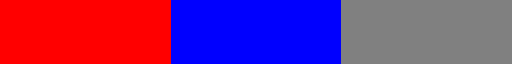

In [135]:
color_palette

In [4]:
image_list =['CF40','CF27','CF35','CF19','CF20','C52E','C56E','C50C','C51E','C48A','ID6','MTS29E','MTS12D','MTS7D','MTS21A','MTS48B','MTS27E','BOS11A','BOS12D','BOS13E']
for i in image_list:
    sample_id=adata[adata.obs['ID'].isin([i])]
    fig, ax = plt.subplots(figsize=(25, 25))
    sq.pl.spatial_scatter(sample_id, color=["BM_Marking",],wspace=0.4, shape=None, ax=ax, 
                          palette=color_palette)
    plt.savefig('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_Mast_Basal/{}_sub.pdf'.format(i), format='pdf')

In [58]:
# Subset for only Mast and Basal cells in the Airway Epithelial Layer
basal_mast = adata[adata.obs['Layers']=='Airway_Ep',]
basal_mast = adata[adata.obs['subtype'].isin(['Basal','Mast']),]

#### Square Root Normalization

In [62]:
# # Store raw data for future use
# basal_mast.raw=basal_mast
# # Normalize data
# sp.pp.normalize_total(basal_mast)
# # Log root normalize the transcript counts
# st.pp.log1p(basal_mast)
# # Run PCA reduction
# st.em.run_pca(basal_mast, n_comps=50,random_state=0)
# st.pp.neighbors(basal_mast, n_neighbors=25,use_rep='X_pca',random_state=0)
st.tl.clustering.louvain(basal_mast, random_state=0)

Applying Louvain cluster ...
Louvain cluster is done! The labels are stored in adata.obs['louvain']


In [66]:
basal_mast

AnnData object with n_obs × n_vars = 94877 × 389
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'duplicates', 'Cell_Class', 'ID', 'subtype', 'Group', 'seurat_clusters', 'Layers', 'cell_ids', 'louvain'
    uns: 'neighbors', 'pca', 'umap', 'log1p', 'louvain'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [1]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (10,10)
st.pl.cluster_plot(basal_mast,use_label="louvain",image_alpha=0,size=1)



In [4]:
pca = PCA()
df=basal_mast.obs['transcript_counts']
# Handle missing values (example: fill with mean)
df = df.fillna(df.mean(numeric_only=True))
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)
#define PCA model to use
pca = PCA(n_components=4)

#fit PCA model to data
pca_fit = pca.fit(scaled_df)
PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_, 'o-', linewidth=2, color='blue')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.show()

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

def plot_scree(data):
    pca = PCA()
    pca.fit(data)
    explained_variance_ratio = pca.explained_variance_ratio_
    cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o', linestyle='-', label='Individual Explained Variance')
    plt.plot(range(1, len(cumulative_variance_ratio) + 1), cumulative_variance_ratio, marker='o', linestyle='--', label='Cumulative Explained Variance')
    plt.title('Scree Plot')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.grid(True)
    plt.legend()
    plt.show()

plot_scree(basal_mast.obs)

#### Niche Plots

In [3]:
adata = sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/Whole_Tissue_All_Layers_Lung.h5ad')
adata.obsm["spatial"] = adata.obsm["spatial"].to_numpy()

/home/haider/miniconda3/envs/nicoUser/lib/python3.11/site-packages/scanpy/plotting/_utils.py:431: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/home/haider/miniconda3/envs/nicoUser/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/haider/miniconda3/envs/nicoUser/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


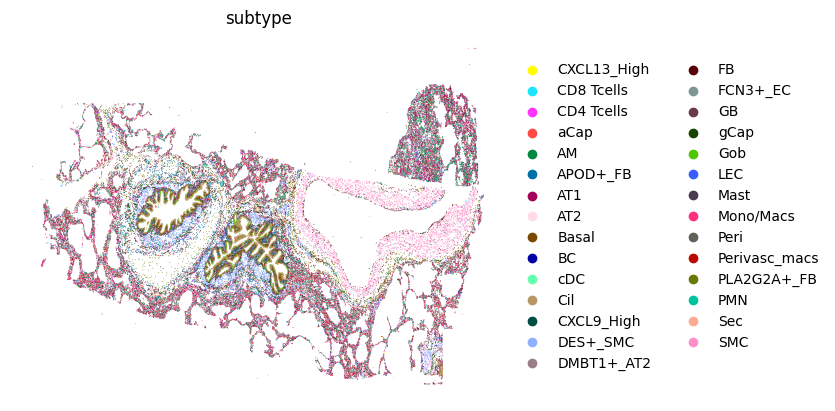

In [4]:
sp.pl.embedding(
    adata[adata.obs['ID'].isin(['MTS12D'])],
    basis="spatial",
    color="subtype",
    frameon=False
)

In [5]:
Airway = adata[~adata.obs['Layers'].isin(['Non-Airway'])]

# CLAD Airway
clad_airway = Airway [Airway.obs['Group'].isin(['BOS'])]
clad_airway = clad_airway[clad_airway.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC', 'CXCL9_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
clad_airway.obs['nico_ct']=clad_airway.obs['subtype']
clad_airway.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/CLAD/clad_airway_nico.h5ad')


# CF Airway
cf_airway = Airway [Airway.obs['Group'].isin(['CF'])]
cf_airway = cf_airway[cf_airway.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
cf_airway.obs['nico_ct']=cf_airway.obs['subtype']
cf_airway.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/CF/cf_airway_nico.h5ad')

# COPD Airway
copd_airway = Airway [Airway.obs['Group'].isin(['COPD'])]
copd_airway = copd_airway[copd_airway.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
copd_airway.obs['nico_ct']=copd_airway.obs['subtype']
copd_airway.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/COPD/copd_airway_nico.h5ad')

# Asthma Airway
asthma_airway = Airway [Airway.obs['Group'].isin(['Asthma'])]
asthma_airway = asthma_airway[asthma_airway.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
asthma_airway.obs['nico_ct']=asthma_airway.obs['subtype']
asthma_airway.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/Asthma/asthma_airway_nico.h5ad')

# HC Airway
hc_airway = Airway [Airway.obs['Group'].isin(['HC'])]
hc_airway = hc_airway[hc_airway.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CXCL9_High', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
hc_airway.obs['nico_ct']=hc_airway.obs['subtype']
hc_airway.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/HC/hc_airway_nico.h5ad')
                         

# nico_CF=Airway_ep_sub[Airway_ep_sub.obs['Group'].isin(['CF'])]
# nico_COPD=Airway_ep_sub[Airway_ep_sub.obs['Group'].isin(['COPD'])]
# nico_BOS=Airway_ep_sub[Airway_ep_sub.obs['Group'].isin(['BOS'])]
# nico_HC=Airway_ep_sub[Airway_ep_sub.obs['Group'].isin(['HC'])]
# nico_Asthma=Airway_ep_sub[Airway_ep_sub.obs['Group'].isin(['Asthma'])]      

# nico_CF.write_h5ad('/home/haider/Squidpy_Spatial_analysis/LTBP2_FB/FB_sub_ep/Nicheplots/CF/nico_CF_sub_ep.h5ad')
# nico_HC.write_h5ad('/home/haider/Squidpy_Spatial_analysis/LTBP2_FB/FB_sub_ep/Nicheplots/HC/nico_HC_sub_ep.h5ad')
# nico_COPD.write_h5ad('/home/haider/Squidpy_Spatial_analysis/LTBP2_FB/FB_sub_ep/Nicheplots/COPD/nico_COPD_sub_ep.h5ad') 
# nico_BOS.write_h5ad('/home/haider/Squidpy_Spatial_analysis/LTBP2_FB/FB_sub_ep/Nicheplots/BOS/nico_BOS_sub_ep.h5ad')
# nico_Asthma.write_h5ad('/home/haider/Squidpy_Spatial_analysis/LTBP2_FB/FB_sub_ep/Nicheplots/Asthma/nico_Asthma_sub_ep.h5ad')

In [19]:
set(hc_airway_ep.obs['Layers'])

{'Airway_Ep'}

In [6]:
Airway_Ep = adata[adata.obs['Layers'].isin(['Airway_Ep'])]

# COPD Airway Ep
copd_airway_ep = Airway_Ep [Airway_Ep.obs['Group'].isin(['COPD'])]
copd_airway_ep = copd_airway_ep[copd_airway_ep.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CD4 Tcells', 'CD8 Tcells'])]
copd_airway_ep.obs['nico_ct']=copd_airway_ep.obs['subtype']
copd_airway_ep.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Ep/COPD/copd_airway_ep_nico.h5ad')

# HC Airway Ep
hc_airway_ep = Airway_Ep [Airway_Ep.obs['Group'].isin(['HC'])]
hc_airway_ep = hc_airway_ep[hc_airway_ep.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CXCL9_High', 'CD4 Tcells', 'CD8 Tcells'])]
hc_airway_ep.obs['nico_ct']=hc_airway_ep.obs['subtype']
hc_airway_ep.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Ep/HC/hc_airway_ep_nico.h5ad')


/tmp/ipykernel_3035039/1717406991.py:7: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  copd_airway_ep.obs['nico_ct']=copd_airway_ep.obs['subtype']
/tmp/ipykernel_3035039/1717406991.py:14: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  hc_airway_ep.obs['nico_ct']=hc_airway_ep.obs['subtype']


In [6]:
# Whole Tissue
asthma_whole = adata [adata.obs['Group'].isin(['Asthma'])]
asthma_whole  = asthma_whole [asthma_whole.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
asthma_whole .obs['nico_ct']=asthma_whole .obs['subtype']
asthma_whole .write_h5ad("/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/Asthma/asthma_whole_nico.h5ad")

hc_whole = adata [adata.obs['Group'].isin(['HC'])]
hc_whole  = hc_whole [hc_whole.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM','CXCL9_High', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
hc_whole .obs['nico_ct']=hc_whole .obs['subtype']
hc_whole .write_h5ad("/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/HC/hc_whole_nico.h5ad")

clad_whole = adata [adata.obs['Group'].isin(['BOS'])]
clad_whole  = clad_whole [clad_whole.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC', 'CXCL9_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
clad_whole .obs['nico_ct']=clad_whole .obs['subtype']
clad_whole .write_h5ad("/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/CLAD/clad_whole_nico.h5ad")

copd_whole = adata [adata.obs['Group'].isin(['COPD'])]
copd_whole = copd_whole[copd_whole.obs['subtype'].isin(['APOD+_FB', 'BC', 'Basal','Cil', 'FB', 'GB', 'Gob', 'Mast', 'Mono/Macs', 'PLA2G2A+_FB', 'PMN', 'Perivasc_macs', 'Sec',
                                                 'CD4 Tcells' 'CD8 Tcells' ,'cDC',  'CXCL13_High', 'AM', 'CD4 Tcells', 'CD8 Tcells', 'AT1', 'AT2', 'aCap', 'gCap'])]
copd_whole.obs['nico_ct']=copd_whole.obs['subtype']
copd_whole.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/COPD/copd_whole_nico.h5ad')

In [8]:
import os
import psutil
import inspect

print("RAM available:", psutil.virtual_memory().available / 1024**3, "GB")
print("RAM total:", psutil.virtual_memory().total / 1024**3, "GB")

print(inspect.signature(sint.spatial_neighborhood_analysis))

RAM available: 491.38247299194336 GB
RAM total: 502.51297760009766 GB
(output_nico_dir=None, anndata_object_name='nico_celltype_annotation.h5ad', spatial_cluster_tag='nico_ct', spatial_coordinate_tag='spatial', Radius=0, n_repeats=1, K_fold=5, seed=36851234, n_jobs=-1, lambda_c_ranges=[0.000244140625, 0.00048828125, 0.0009765625, 0.001953125, 0.00390625, 0.0078125, 0.015625, 0.03125, 0.0625, 0.125, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 128.0, 256.0, 512.0, 1024.0, 2048.0], epsilonThreshold=100, removed_CTs_before_finding_CT_CT_interactions=[])


average neighbors: 19.56103729599647
average distance: 13.418987808285621
data shape (284755, 25) (284755,) neighbor shape (284755, 23)
Searching hyperparameters  Grid method: 2048.0
Searching hyperparameters  Grid method: 0.0625
Searching hyperparameters  Grid method: 0.0625
Inverse of lambda regularization found 0.0625
training (227804, 23) testing (56951, 23) coeff (23, 23)
The figures are saved:  /home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/HC/niche_prediction_linear/Niche_interactions_with_edge_weights_R20.pdf
average neighbors: 19.772982509848784
average distance: 13.385840953209144
data shape (247835, 24) (247835,) neighbor shape (247835, 22)
Searching hyperparameters  Grid method: 0.015625
Searching hyperparameters  Grid method: 0.00390625
Searching hyperparameters  Grid method: 0.001953125
Searching hyperparameters  Grid method: 0.001953125
Inverse of lambda regularization found 0.001953125
training (198268, 22) testing (49567, 22) coeff (22, 22)
T

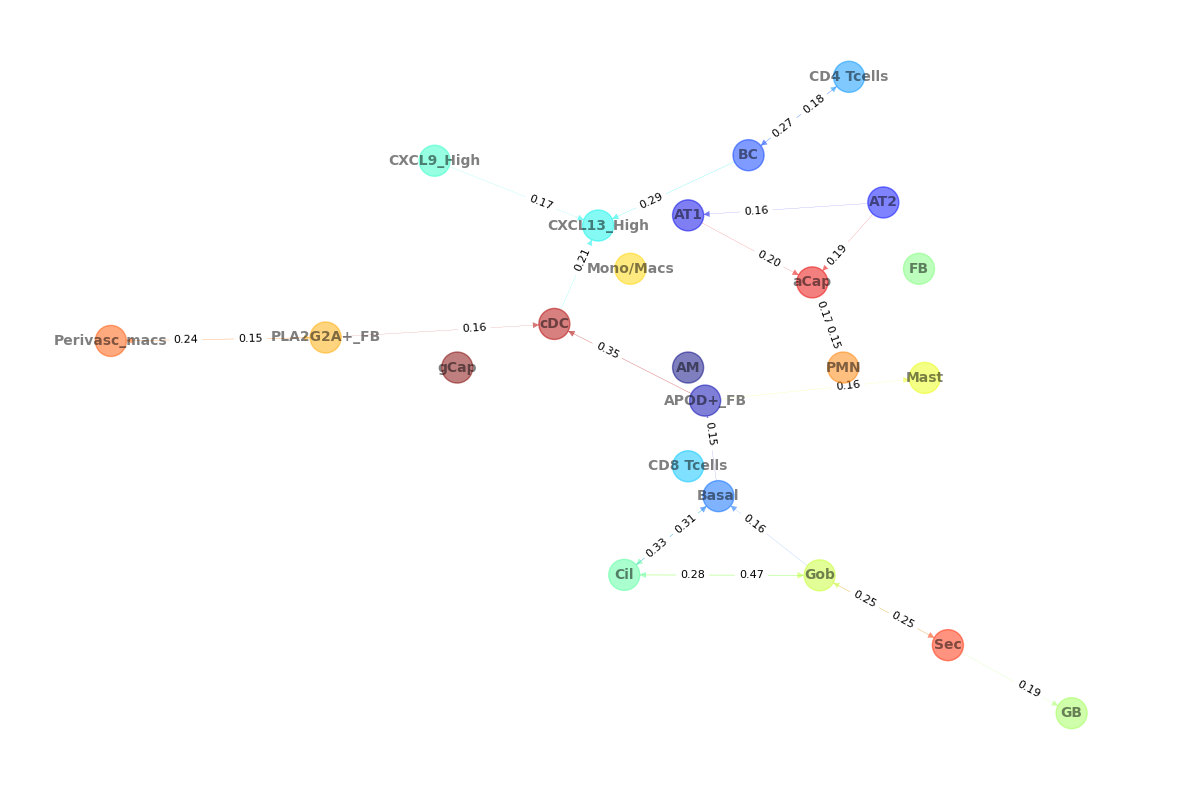

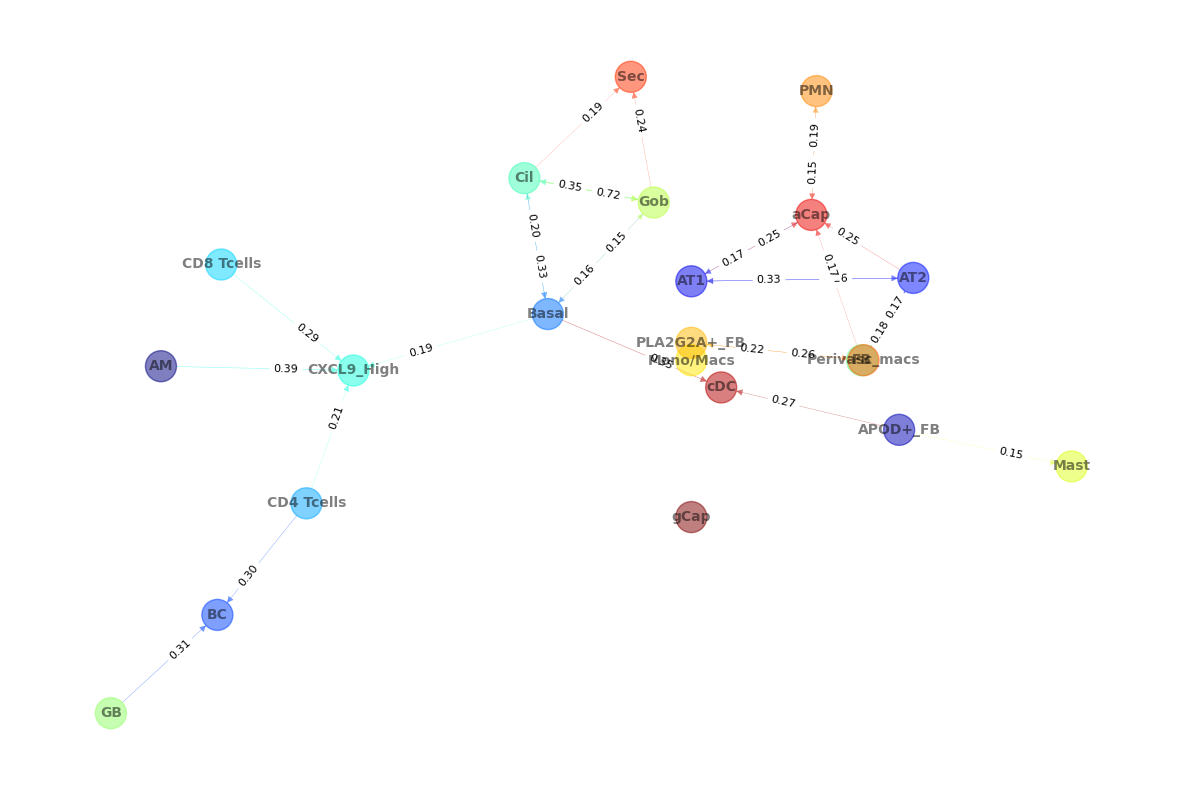

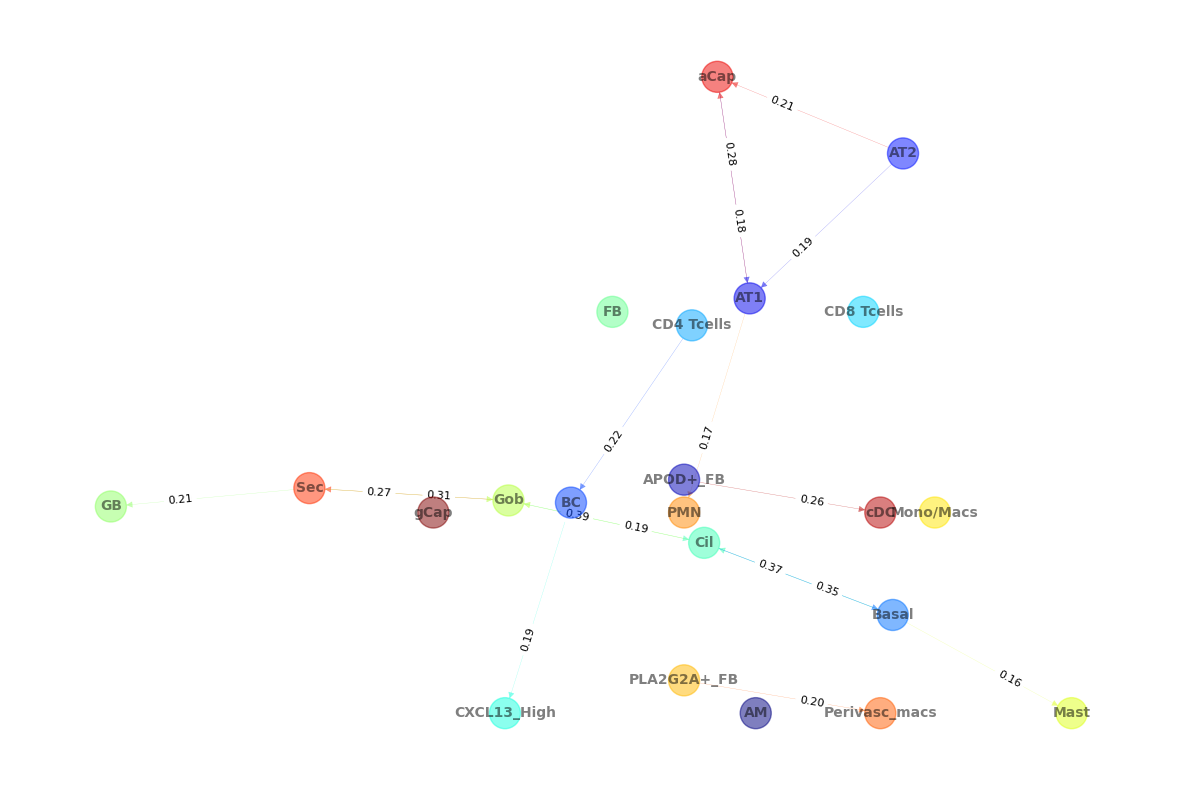

In [5]:
def niche_interaction(files):
    for i in range(len(files)):
        niche_pred_output=sint.spatial_neighborhood_analysis(
            Radius=20,
            output_nico_dir=files[i][1],
            anndata_object_name=files[i][0],
            spatial_cluster_tag='nico_ct', n_jobs=15)
        sint.plot_niche_interactions_with_edge_weight(niche_pred_output,
                                                      niche_cutoff=0.15,
                                                      saveas='pdf',
                                                      transparent_mode=False,
                                                      showit=True,
                                                      figsize=(15, 10),
                                                      dpi=300,
                                                      input_colormap='jet',
                                                      with_labels=True,
                                                      node_size=500,
                                                      linewidths=1,
                                                      node_font_size=10,
                                                      alpha=0.5,
                                                      font_weight='bold',
                                                      edge_label_pos=0.35,   #Relative position of the weight label along the edge.
                                                      edge_font_size=8     #Font size for edge labels.
                                                 )
        

# Airway Analysis
# niche_interaction([['hc_airway_nico.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/HC/']])
# niche_interaction([['copd_airway_nico.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/COPD/']])
# niche_interaction([['asthma_airway_nico.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/Asthma/']])
# niche_interaction([['clad_airway_nico.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/CLAD/']])
# niche_interaction([['cf_airway_nico.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Full/CF/']])

# Airway Ep
# niche_interaction([['hc_airway_ep_nico.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Ep/HC/'],
#                     ['copd_airway_ep_nico.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Ep/COPD/']])
# niche_interaction( [['copd_airway_ep_nico.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Airway_Ep/COPD/']])

# Whole Tissue
# niche_interaction([["asthma_whole_nico.h5ad", "/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/Asthma/"]])
niche_interaction([["hc_whole_nico.h5ad", "/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/HC/"]])
niche_interaction([["clad_whole_nico.h5ad", "/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/CLAD/"]])
niche_interaction([["copd_whole_nico.h5ad", "/home/haider/Squidpy_Spatial_analysis/Airway/NichePlots_2026/Whole_Tissue/COPD/"]])

#### Final Receptor-Ligand Analysis (Ep, Endo, Mess and Immune)

In [126]:
airway_final = sp.read_h5ad("/media/haider/Files/Squidpy_Spatial_analysis/annot_v3_xenium.h5ad")
airway_final

AnnData object with n_obs × n_vars = 1890517 × 389
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'nCount_BlankCodeword', 'nFeature_BlankCodeword', 'nCount_ControlCodeword', 'nFeature_ControlCodeword', 'nCount_ControlProbe', 'nFeature_ControlProbe', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.3', 'seurat_clusters', 'celltypes', 'Group', 'ID', 'SCT_snn_res.0.7', 'subtype', 'Cell_Class', 'Layers', 'ident'
    uns: 'X_name'
    obsm: 'HARMONY', 'PCA', 'UMAP'

In [127]:
set(airway_final.obs['subtype'])

{'AM',
 'APOD+_FB',
 'AT1',
 'AT2',
 'BC',
 'Basal',
 'CD4 Tcells',
 'CD8 Tcells',
 'CXCL+_Immune',
 'CXCL9_High',
 'Cil',
 'DES+_SMC',
 'DMBT1+_AT2',
 'FB',
 'FCN3+_EC',
 'GB',
 'Gob',
 'LEC',
 'Mast',
 'Mono/Macs',
 'PLA2G2A+_FB',
 'PMN',
 'Peri',
 'Perivasc_macs',
 'SMC',
 'Sec',
 'aCap',
 'cDC',
 'gCap'}

In [128]:
set(airway_final.obs['Layers'])

{'Airway_Ep', 'Non-Airway', 'SMG', 'Sub_Ep'}

In [129]:
# create basal mast objects
basal_mast = airway_final[airway_final.obs['subtype'].isin(['Basal', 'Mast'])]
# create bc basal objects
basal_bc = airway_final[airway_final.obs['subtype'].isin(['Basal', 'BC'])]
# create gb basal objects
basal_gb = airway_final[airway_final.obs['subtype'].isin(['Basal', 'GB'])]
# create cxcl+ bc objects
cxcl_bc = airway_final[airway_final.obs['subtype'].isin(['CXCL+_Immune', 'BC'])]
# create CD4 and Mono/Macs objects
mono_tcell = airway_final[airway_final.obs['subtype'].isin(['CD8 Tcells', 'Mono/Macs'])]
# create CD4 and Mono/Macs objects
perivasc_tcell = airway_final[airway_final.obs['subtype'].isin(['CD8 Tcells',  'Perivasc_macs'])]
# create CD4 and AM objects
am_tcell = airway_final[airway_final.obs['subtype'].isin(['CD8 Tcells',  'AM'])]
# create bc and Sec objects
bc_sec = airway_final[airway_final.obs['subtype'].isin(['Sec',  'BC'])]
# create cxcl9 and cd4 objects
cxcl9_cd4 = airway_final[airway_final.obs['subtype'].isin(['CXCL9_High',  'CD4 Tcells'])]
# create cxcl9 and cd8 objects
cxcl9_cd8 = airway_final[airway_final.obs['subtype'].isin(['CXCL9_High',  'CD8 Tcells'])]
# create cxcl9 and am objects
cxcl9_am = airway_final[airway_final.obs['subtype'].isin(['CXCL9_High',  'AM'])]

In [58]:
obj2=basal_mast[basal_mast.obs['Group'].isin(['COPD'])]
res = sq.gr.ligrec(obj2, "subtype",
                       fdr_method=None, copy=True,use_raw=False,
                       transmitter_params={"categories": "ligand"},
                       receiver_params={"categories": "receptor"},
                       threshold=0, seed=0, n_perms=1000, n_jobs=1)
res

  0%|          | 0/1000 [00:00<?, ?permutation/s]

{'means': cluster_1           Basal                Mast          
 cluster_2           Basal      Mast     Basal      Mast
 source target                                          
 EGF    EGFR      0.482904  0.035551  0.502092   0.05474
 CD80   CD28      0.022867  0.027304   0.02445  0.028888
 CD40LG CD40      0.084106  0.023479  0.090494  0.029867
 CD70   CD27       0.00631  0.009238  0.006767  0.009694
 FAS    FASLG     0.185093  0.192639  0.046117  0.053662
 ...                   ...       ...       ...       ...
 CP     PRKCD     0.338825  0.230699  0.229356   0.12123
 EGF    PRKCD     0.216239  0.108113  0.235427  0.127301
        HSP90AB1  0.436226  0.092934  0.455414  0.112123
        BMX       0.008575  0.011168  0.027764  0.030356
 IL13   PRKCD     0.215295  0.107169  0.220053  0.111927
 
 [149 rows x 4 columns],
 'pvalues': cluster_1        Basal          Mast       
 cluster_2        Basal   Mast  Basal   Mast
 source target                              
 EGF    EGFR        

In [63]:
significant_mask = ((res['pvalues'] < 0.05) & (res['means'] > 0.6)).any(axis=1)
significant_indices = res['pvalues'].index[significant_mask]

# 2. Subset all three dataframes inside the dictionary using the significant indices
filtered_res = {
    'means': res['means'].loc[significant_indices],
    'pvalues': res['pvalues'].loc[significant_indices],
    'metadata': res['metadata'].loc[significant_indices]
}

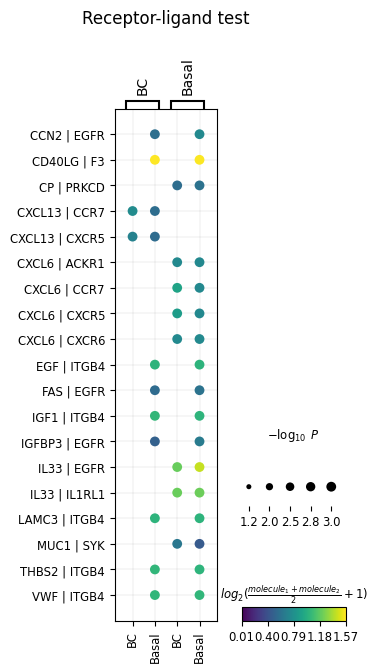

In [57]:
sq.pl.ligrec(filtered_res, source_groups=['Basal', 'BC'], alpha=None)

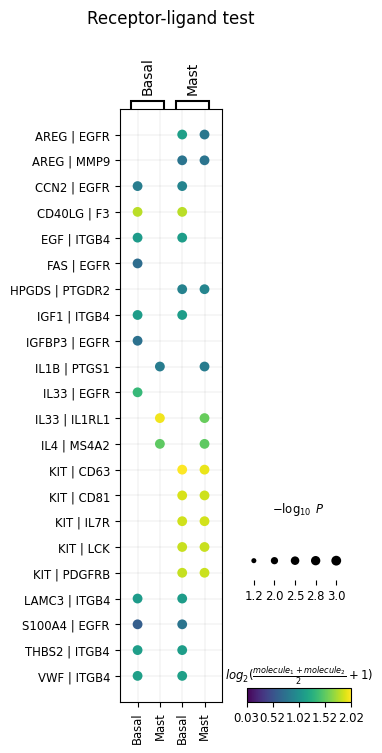

In [64]:
sq.pl.ligrec(filtered_res, source_groups=['Basal', 'Mast'], alpha=None)

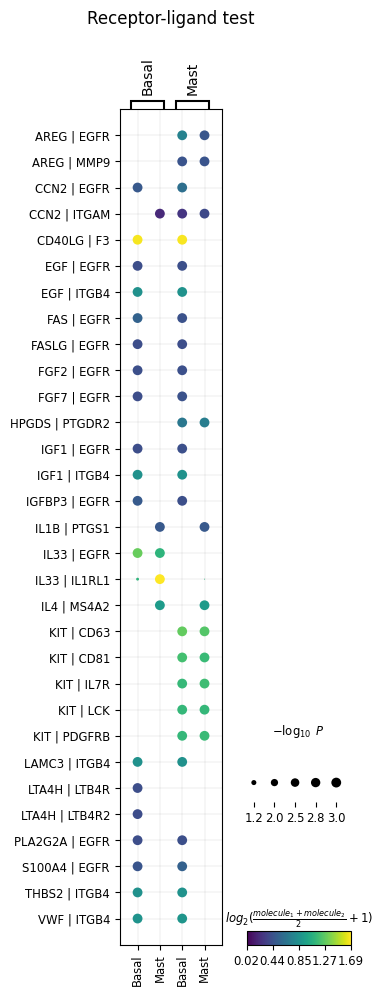

In [45]:
sq.pl.ligrec(filtered_res, source_groups=['Basal', 'Mast'], alpha=None)

sanity check:{'CLAD'}
sanity check:{'Airway_Ep', 'SMG', 'Sub_Ep', 'Non-Airway'}


100%|████████████████████████████| 1000/1000 [00:01<00:00, 530.02permutation/s]


permutation finished
sanity check:{'CLAD'}
sanity check:{'Airway_Ep', 'Sub_Ep', 'Non-Airway'}


100%|████████████████████████████| 1000/1000 [00:01<00:00, 976.56permutation/s]


permutation finished
sanity check:{'CLAD'}
sanity check:{'Airway_Ep', 'SMG', 'Sub_Ep', 'Non-Airway'}


...

permutation finished
sanity check:{'CLAD'}
sanity check:{'Airway_Ep', 'Sub_Ep'}


100%|███████████████████████████| 1000/1000 [00:00<00:00, 2242.85permutation/s]


permutation finished
sanity check:{'CLAD'}
sanity check:{'Airway_Ep', 'Sub_Ep', 'SMG'}


100%|███████████████████████████| 1000/1000 [00:00<00:00, 2087.32permutation/s]


permutation finished


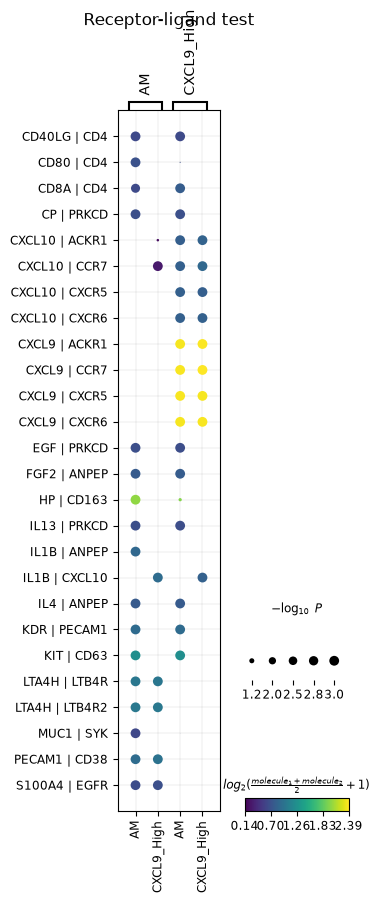

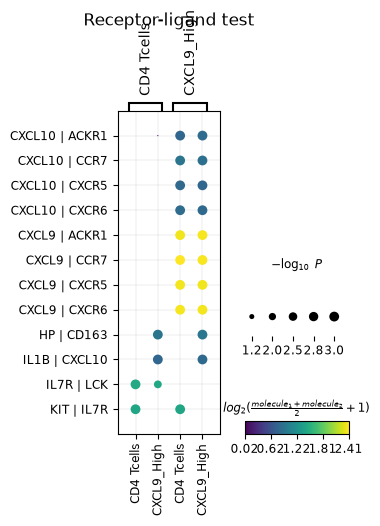

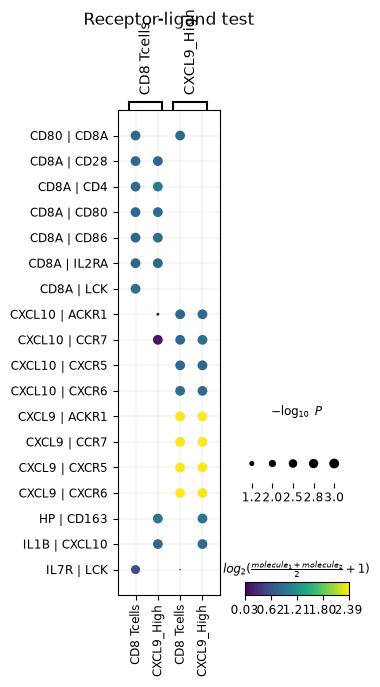

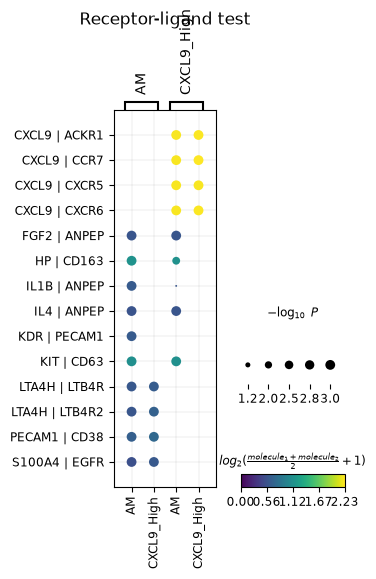

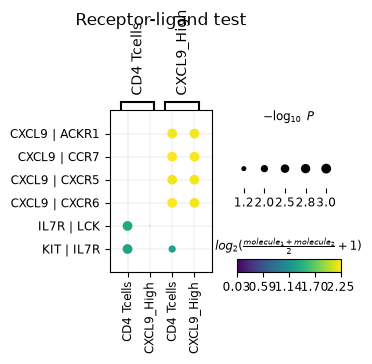

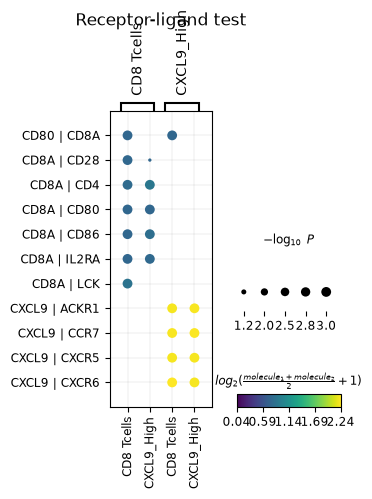

In [130]:
# Global Analysis
def receptor_ligand(disease_group, sub1, sub2, obj):
    obj=obj[obj.obs['Group'].isin([disease_group])]
    print('sanity check:{}'.format(set(obj.obs['Group'])))
    print('sanity check:{}'.format(set(obj.obs['Layers'])))
    res = sq.gr.ligrec(obj, "subtype",
                       fdr_method=None, copy=True,use_raw=False,
                       transmitter_params={"categories": "ligand"},
                       receiver_params={"categories": "receptor"},
                       threshold=0, seed=0, n_perms=1000, n_jobs=1)
    

    significant_mask = ((res['pvalues'] < 0.05) & (res['means'] > 0.5)).any(axis=1)
    significant_indices = res['pvalues'].index[significant_mask]

    # 2. Subset all three dataframes inside the dictionary using the significant indices
    filtered_res = {
        'means': res['means'].loc[significant_indices],
        'pvalues': res['pvalues'].loc[significant_indices],
        'metadata': res['metadata'].loc[significant_indices]}
    print('permutation finished')
    sq.pl.ligrec(filtered_res, source_groups=[sub1, sub2], save='/home/haider/Squidpy_Spatial_analysis/Airway/{}_{}_{}_RL_whole_tissue.pdf'.format(sub1, sub2, disease_group), alpha=None)
# receptor_ligand('Asthma', 'Basal', 'Mast', basal_mast)
# receptor_ligand('COPD', 'Basal', 'Mast', basal_mast)
# receptor_ligand('CF', 'Basal', 'BC', basal_bc)
# receptor_ligand('CF', 'Basal', 'GB', basal_gb)
# receptor_ligand('CF', 'CXCL+_Immune', 'BC', cxcl_bc)
# receptor_ligand('CLAD','Perivasc_macs' , 'CD8 Tcells', perivasc_tcell)
# receptor_ligand('CLAD','AM' , 'CD8 Tcells', am_tcell)
# receptor_ligand('CLAD', 'Mono/Macs', 'CD8 Tcells', mono_tcell)
# receptor_ligand('Asthma', 'Sec', 'BC', bc_sec)
receptor_ligand('CLAD', 'CXCL9_High', 'AM', cxcl9_am)
receptor_ligand('CLAD', 'CXCL9_High', 'CD4 Tcells', cxcl9_cd4)
receptor_ligand('CLAD', 'CXCL9_High', 'CD8 Tcells', cxcl9_cd8)

# Just Airway Analysis
def receptor_ligand_2(disease_group, sub1, sub2, obj):
    obj=obj[obj.obs['Group'].isin([disease_group])]
    obj=obj[~obj.obs['Layers'].isin(['Non-Airway'])]
    print('sanity check:{}'.format(set(obj.obs['Group'])))
    print('sanity check:{}'.format(set(obj.obs['Layers'])))
    res = sq.gr.ligrec(obj, "subtype",
                       fdr_method=None, copy=True,use_raw=False,
                       transmitter_params={"categories": "ligand"},
                       receiver_params={"categories": "receptor"},
                       threshold=0, seed=0, n_perms=1000, n_jobs=1)
    

    significant_mask = ((res['pvalues'] < 0.05) & (res['means'] > 0.5)).any(axis=1)
    significant_indices = res['pvalues'].index[significant_mask]

    # 2. Subset all three dataframes inside the dictionary using the significant indices
    filtered_res = {
        'means': res['means'].loc[significant_indices],
        'pvalues': res['pvalues'].loc[significant_indices],
        'metadata': res['metadata'].loc[significant_indices]}
    print('permutation finished')
    sq.pl.ligrec(filtered_res, source_groups=[sub1, sub2], save='/home/haider/Squidpy_Spatial_analysis/Airway/{}_{}_{}_RL_airway_layers.pdf'.format(sub1, sub2, disease_group), alpha=None)

# receptor_ligand_2('Asthma', 'Basal', 'Mast', basal_mast)
# receptor_ligand_2('COPD', 'Basal', 'Mast', basal_mast)
# receptor_ligand_2('CF', 'Basal', 'BC', basal_bc)
# receptor_ligand_2('CF', 'Basal', 'GB', basal_gb)
# receptor_ligand_2('CF', 'CXCL+_Immune', 'BC', cxcl_bc)
# receptor_ligand_2('Asthma', 'Sec', 'BC', bc_sec)
# receptor_ligand_2('CLAD', 'Mono/Macs', 'CD8 Tcells', mono_tcell)
# receptor_ligand_2('CLAD','Perivasc_macs' , 'CD8 Tcells', perivasc_tcell)
# receptor_ligand_2('CLAD','AM' , 'CD8 Tcells', am_tcell)
receptor_ligand_2('CLAD', 'CXCL9_High', 'AM', cxcl9_am)
receptor_ligand_2('CLAD', 'CXCL9_High', 'CD4 Tcells', cxcl9_cd4)
receptor_ligand_2('CLAD', 'CXCL9_High', 'CD8 Tcells', cxcl9_cd8)

sanity check:{'CLAD'}
sanity check:{'Sub_Ep', 'Airway_Ep'}


  0%|          | 0/1000 [00:00<?, ?permutation/s]

permutation finished


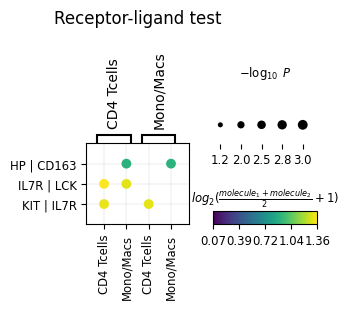

In [80]:
# Just Airway Ep and SubEp Analysis
def receptor_ligand_3(disease_group, sub1, sub2, obj):
    obj=obj[obj.obs['Group'].isin([disease_group])]
    obj=obj[obj.obs['Layers'].isin(['Airway_Ep','Sub_Ep'])]
    print('sanity check:{}'.format(set(obj.obs['Group'])))
    print('sanity check:{}'.format(set(obj.obs['Layers'])))
    res = sq.gr.ligrec(obj, "subtype",
                       fdr_method=None, copy=True,use_raw=False,
                       transmitter_params={"categories": "ligand"},
                       receiver_params={"categories": "receptor"},
                       threshold=0, seed=0, n_perms=1000, n_jobs=1)
    

    significant_mask = ((res['pvalues'] < 0.05) & (res['means'] > 0.5)).any(axis=1)
    significant_indices = res['pvalues'].index[significant_mask]

    # 2. Subset all three dataframes inside the dictionary using the significant indices
    filtered_res = {
        'means': res['means'].loc[significant_indices],
        'pvalues': res['pvalues'].loc[significant_indices],
        'metadata': res['metadata'].loc[significant_indices]}
    print('permutation finished')
    sq.pl.ligrec(filtered_res, source_groups=[sub1, sub2], save='/home/haider/Squidpy_Spatial_analysis/Airway/{}_{}_{}_RL_airwayep_sub_layers.pdf'.format('Mono', sub2, disease_group), alpha=None)

# receptor_ligand_3('Asthma', 'Basal', 'Mast', basal_mast)
# receptor_ligand_3('COPD', 'Basal', 'Mast', basal_mast)
# receptor_ligand_3('CF', 'Basal', 'BC', basal_bc)
# receptor_ligand_3('CF', 'Basal', 'GB', basal_gb)
# receptor_ligand_3('CF', 'CXCL+_Immune', 'BC', cxcl_bc)
# receptor_ligand_3('CLAD', 'Mono/Macs', 'CD4 Tcells', mono_tcell)

#### Calculate Celltype Contact Frequency

In [4]:
Airway_Ep = adata[adata.obs['Layers'].isin(['Airway_Ep'])]
Airway = adata[~adata.obs['Layers'].isin(['Non-Airway'])]
print(set(Airway_Ep.obs['Layers']))
print(set(Airway.obs['Layers']))

{'Airway_Ep'}
{'Airway_Ep', 'Sub_Ep', 'SMG'}


In [25]:
basal_mast_airway = Airway[Airway.obs['subtype'].isin(['Basal', 'Mast'])]
print(set(basal_mast_airway.obs['Layers']))
print(set(basal_mast_airway.obs['subtype']))

basal_mast_airway_ep = Airway_Ep[Airway_Ep.obs['subtype'].isin(['Basal', 'Mast'])]
print(set(basal_mast_airway_ep.obs['Layers']))
print(set(basal_mast_airway_ep.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep'}
{'Basal', 'Mast'}
{'Airway_Ep'}
{'Basal', 'Mast'}


In [26]:
bc_sec_airway = Airway[Airway.obs['subtype'].isin(['BC', 'Sec'])]
print(set(bc_sec_airway.obs['Layers']))
print(set(bc_sec_airway.obs['subtype']))

{'Sub_Ep', 'SMG', 'Airway_Ep'}
{'BC', 'Sec'}


In [5]:
gb_sec_airway = Airway[Airway.obs['subtype'].isin(['GB', 'Sec'])]
print(set(gb_sec_airway.obs['Layers']))
print(set(gb_sec_airway.obs['subtype']))

{'Airway_Ep', 'Sub_Ep', 'SMG'}
{'GB', 'Sec'}


In [27]:
cxcl9_macs_airway = Airway[Airway.obs['subtype'].isin(['CXCL9_High', 'Mono/Macs', 'AM',
                                                      'Perivasc_macs'])]
print(set(cxcl9_macs_airway.obs['Layers']))
print(set(cxcl9_macs_airway.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep'}
{'Mono/Macs', 'Perivasc_macs', 'CXCL9_High', 'AM'}


In [25]:
cxcl9_am_whole = adata[adata.obs['subtype'].isin(['CXCL9_High', 'AM'])]
print(set(cxcl9_am_whole.obs['Layers']))
print(set(cxcl9_am_whole.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep', 'Non-Airway'}
{'CXCL9_High', 'AM'}


In [21]:
cxcl9_macs_whole = adata[adata.obs['subtype'].isin(['CXCL9_High', 'Mono/Macs'])]
print(set(cxcl9_macs_whole.obs['Layers']))
print(set(cxcl9_macs_whole.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep', 'Non-Airway'}
{'CXCL9_High', 'Mono/Macs'}


In [28]:
cxcl13_bc_airway = Airway[Airway.obs['subtype'].isin(['CXCL13_High', 'BC'])]
print(set(cxcl13_bc_airway.obs['Layers']))
print(set(cxcl13_bc_airway.obs['subtype']))

{'Sub_Ep', 'SMG', 'Airway_Ep'}
{'CXCL13_High', 'BC'}


In [29]:
basal_gb_airway = Airway[Airway.obs['subtype'].isin(['Basal', 'GB'])]
print(set(basal_gb_airway.obs['Layers']))
print(set(basal_gb_airway.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep'}
{'Basal', 'GB'}


In [30]:
bc_gb_airway = Airway[Airway.obs['subtype'].isin(['BC', 'GB'])]
print(set(bc_gb_airway.obs['Layers']))
print(set(bc_gb_airway.obs['subtype']))

{'Sub_Ep', 'SMG', 'Airway_Ep'}
{'BC', 'GB'}


In [31]:
tcell_macs_airway = Airway[Airway.obs['subtype'].isin(['CD4 Tcells','CD8 Tcells', 'Mono/Macs',
                                                      'AM', 'Perivasc_macs'])]
print(set(tcell_macs_airway.obs['Layers']))
print(set(tcell_macs_airway.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep'}
{'Perivasc_macs', 'CD8 Tcells', 'CD4 Tcells', 'Mono/Macs', 'AM'}


In [32]:
cxcl13_basal_airway = Airway[Airway.obs['subtype'].isin(['CXCL13_High', 'Basal'])]
print(set(cxcl13_basal_airway.obs['Layers']))
print(set(cxcl13_basal_airway.obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep'}
{'CXCL13_High', 'Basal'}


In [32]:
cxcl9_basal_airway = Airway[Airway.obs['subtype'].isin(['CXCL9_High', 'Basal'])]
print(set(cxcl9_basal_airway .obs['Layers']))
print(set(cxcl9_basal_airway .obs['subtype']))

{'Airway_Ep', 'Sub_Ep', 'SMG'}
{'Basal', 'CXCL9_High'}


In [36]:
cxcl9_cd4_airway = Airway[Airway.obs['subtype'].isin(['CXCL9_High', 'CD4 Tcells'])]
print(set(cxcl9_cd4_airway .obs['Layers']))
print(set(cxcl9_cd4_airway .obs['subtype']))

{'Airway_Ep', 'Sub_Ep', 'SMG'}
{'CD4 Tcells', 'CXCL9_High'}


In [119]:
cxcl9_cd4_whole = adata[adata.obs['subtype'].isin(['CXCL9_High', 'CD4 Tcells'])]
print(set(cxcl9_cd4_whole .obs['Layers']))
print(set(cxcl9_cd4_whole .obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep', 'Non-Airway'}
{'CD4 Tcells', 'CXCL9_High'}


In [120]:
cxcl9_cd8_whole = adata[adata.obs['subtype'].isin(['CXCL9_High', 'CD8 Tcells'])]
print(set(cxcl9_cd8_whole .obs['Layers']))
print(set(cxcl9_cd8_whole .obs['subtype']))

{'Airway_Ep', 'SMG', 'Sub_Ep', 'Non-Airway'}
{'CD8 Tcells', 'CXCL9_High'}


In [39]:
cxcl9_cd8_airway = Airway[Airway.obs['subtype'].isin(['CXCL9_High', 'CD8 Tcells'])]
print(set(cxcl9_cd8_airway .obs['Layers']))
print(set(cxcl9_cd8_airway .obs['subtype']))

{'Airway_Ep', 'Sub_Ep', 'SMG'}
{'CD8 Tcells', 'CXCL9_High'}


In [9]:
import pandas as pd
import numpy as np

def calculate_contact_freq(obj, disease):
    # calcualte spatial coordinates
    obj = obj[obj.obs['Group'].isin([disease])]
    print(set(obj.obs['Group']))
    sq.gr.spatial_neighbors(
    obj,
    coord_type='generic',
    radius=10)
    # Get celltypes
    cell_types = obj.obs["subtype"].astype(str).values
    types = sorted(pd.unique(cell_types))
    # extract spatial interaction information amonst celltypes
    A = obj.obsp["spatial_connectivities"]

    contact_freq = pd.DataFrame(
        0.0,
        index=types,
        columns=types)

    for ct in types:
        cells = np.where(cell_types == ct)[0]

        for target in types:
            target_cells = cell_types == target

            # Number of neighbors of ct cells that are target
            contacts = A[cells][:, target_cells].sum()

            # Total number of neighbors of ct cells
            total = A[cells].sum()

            if total > 0:
                contact_freq.loc[ct, target] = contacts / total
    print(contact_freq)
    return contact_freq
    

In [10]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_contact_absolute_difference(control_matrix, disease_matrix,
                                     control_name,
                                     disease_name, filename, directory,
                                     figsize=(10, 6)):
    """
    Calculate and plot absolute difference in directional contact frequency.

    Absolute difference = disease - control

    Input matrices should contain proportions (e.g. 0.0063).
    The difference is converted to percentage points (pp).
    """

    # Make sure matrices are DataFrames
    control_matrix = pd.DataFrame(control_matrix)
    disease_matrix = pd.DataFrame(disease_matrix)

    # Check that cell types match
    if not control_matrix.index.equals(disease_matrix.index):
        raise ValueError("Row cell types do not match.")

    if not control_matrix.columns.equals(disease_matrix.columns):
        raise ValueError("Column cell types do not match.")

    # Calculate difference
    difference = disease_matrix - control_matrix

    # Convert from proportion to percentage points
    difference_pp = difference * 100

    # Convert matrix to long format
    plot_data = difference_pp.stack().reset_index()
    plot_data.columns = ["Source", "Target", "Difference"]

    # Interaction labels
    plot_data["Interaction"] = (
        plot_data["Source"] + " → " + plot_data["Target"]
    )

    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(
        plot_data["Interaction"],
        plot_data["Difference"],
        color=[
            "#0072B2",
            "#E69F00",
            "#009E73",
            "#CC79A7",
            "#56B4E9",
            "#D55E00",
            "#F0E442",
            "#000000",
            "#332288",
            "#117733",
            "#44AA99",
            "#88CCEE",
            "#DDCC77",
            "#AA4499",
            "#CC6677",
            "#882255",
            "#661100",
            "#999933",
            "#6699CC",
            "#AA4466",
            "#447744",
            "#774C8E",
            "#CC8844",
            "#4477AA",
            "#999999"
        ]
    )

    # Zero-change line
    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_ylabel(
        f"Change in contact frequency (percentage points)\n"
        f"{disease_name} − ND"
    )

    ax.set_xlabel("Cell-cell interaction")
    ax.set_title("Directional Spatial Contact Frequency")

    plt.xticks(rotation=45, ha="right")

    # Add labels
    for bar, value in zip(bars, plot_data["Difference"]):

        # Dynamic offset based on plot scale
        offset = max(abs(plot_data["Difference"])) * 0.04

        if value >= 0:
            y_position = value + offset
            vertical_alignment = "bottom"
        else:
            y_position = value - offset
            vertical_alignment = "top"

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            y_position,
            f"{value:+.2f} pp",
            ha="center",
            va=vertical_alignment,
            fontsize=9
        )

    # Add a little space above/below bars for labels
    max_abs = max(abs(plot_data["Difference"]))

    ax.set_ylim(
        -max_abs * 1.25,
        max_abs * 1.25
    )

    plt.tight_layout()

    # Save
    out = directory + filename
    plt.savefig(
        out,
        format="pdf",
        bbox_inches="tight"
    )

    plt.show()

    return difference_pp

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def plot_intercelltype_contacts(condition1, condition2, ctrl, disease, filename, dirt):
    
    # Remove intra-celltype interactions
    condition1 = condition1.copy()
    condition2 = condition2.copy()

    np.fill_diagonal(condition1.values, np.nan)
    np.fill_diagonal(condition2.values, np.nan)

    # Convert to long format
    condition1_df = condition1.stack().reset_index()
    condition1_df.columns = ["Source", "Target", "Contact_Frequency"]

    condition2_df = condition2.stack().reset_index()
    condition2_df.columns = ["Source", "Target", "Contact_Frequency"]

    # Interaction labels
    condition1_df["Interaction"] = (
        condition1_df["Source"] + " → " + condition1_df["Target"]
    )

    condition2_df["Interaction"] = (
        condition2_df["Source"] + " → " + condition2_df["Target"]
    )

    # Get interactions in consistent order
    interactions = condition1_df["Interaction"].tolist()

    # Plot
    x = np.arange(len(interactions))
    width = 0.35

    condition1_values = [
        condition1_df.loc[
            condition1_df["Interaction"] == interaction,
            "Contact_Frequency"
        ].iloc[0]
        for interaction in interactions
    ]

    condition2_values = [
        condition2_df.loc[
            condition2_df["Interaction"] == interaction,
            "Contact_Frequency"
        ].iloc[0]
        for interaction in interactions
    ]

    plt.figure(figsize=(10, 8))

    plt.bar(
        x - width/2,
        condition1_values,
        width,
        label=ctrl
    )

    plt.bar(
        x + width/2,
        condition2_values,
        width,
        label=disease
    )

    plt.ylabel("Contact Frequency")
    plt.xlabel("Cell–Cell Interaction")
    plt.xticks(x, interactions, rotation=45, ha="right")
    plt.legend()

    plt.tight_layout()

    # Save
    out = f'{dirt}/{filename}'
    plt.savefig(
        out,
        format="pdf",
        bbox_inches="tight"
    )

    plt.show()

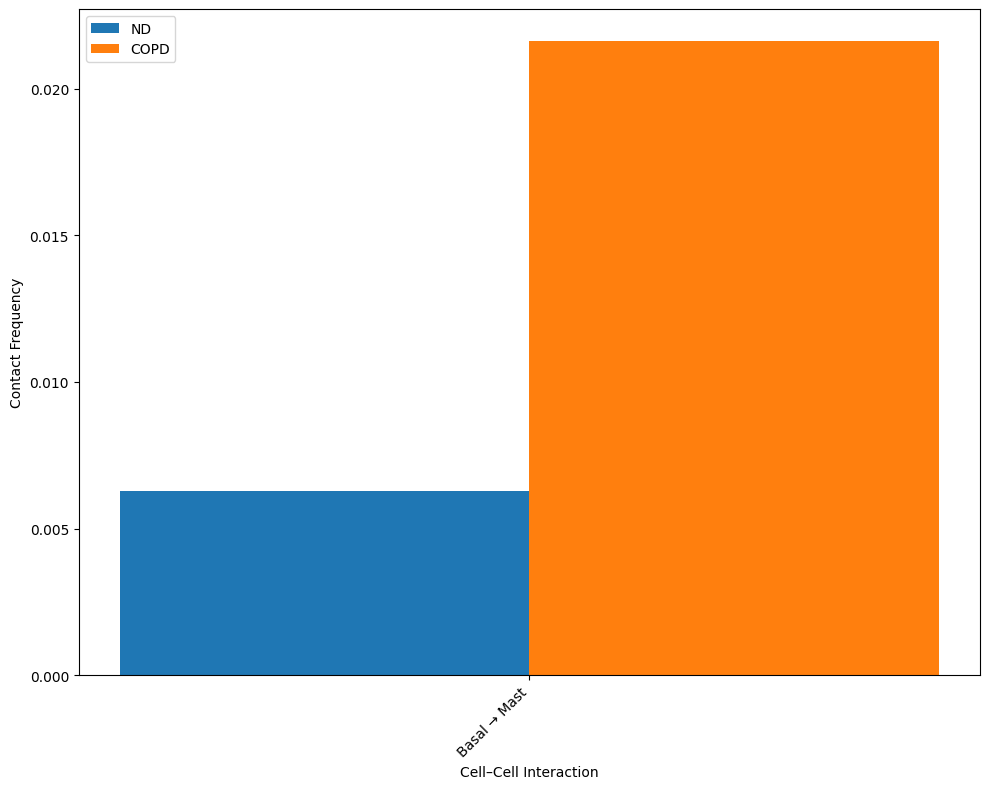

In [162]:
# basal_mast_airway_ep_contact_hc = calculate_contact_freq(basal_mast_airway_ep, 'HC')
# pd.DataFrame(basal_mast_airway_ep_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/basal_mast_hc_airway_ep.csv')


# basal_mast_airway_ep_contact_copd = calculate_contact_freq(basal_mast_airway_ep, 'COPD')
# pd.DataFrame(basal_mast_airway_ep_contact_copd).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/basal_mast_copd_airway_ep.csv')

# plot_contact_absolute_difference(basal_mast_airway_ep_contact_hc, basal_mast_airway_ep_contact_copd, 'HC', 'COPD', 'basal_mast_contact_frequency_hc_copd_airway_ep.pdf', 
#                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/')
plot_intercelltype_contacts(basal_mast_airway_ep_contact_hc[0:1], basal_mast_airway_ep_contact_copd[0:1],'ND',  'COPD', 'basal_mast_contact_frequency_focused_hc_copd_airway_ep.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/')

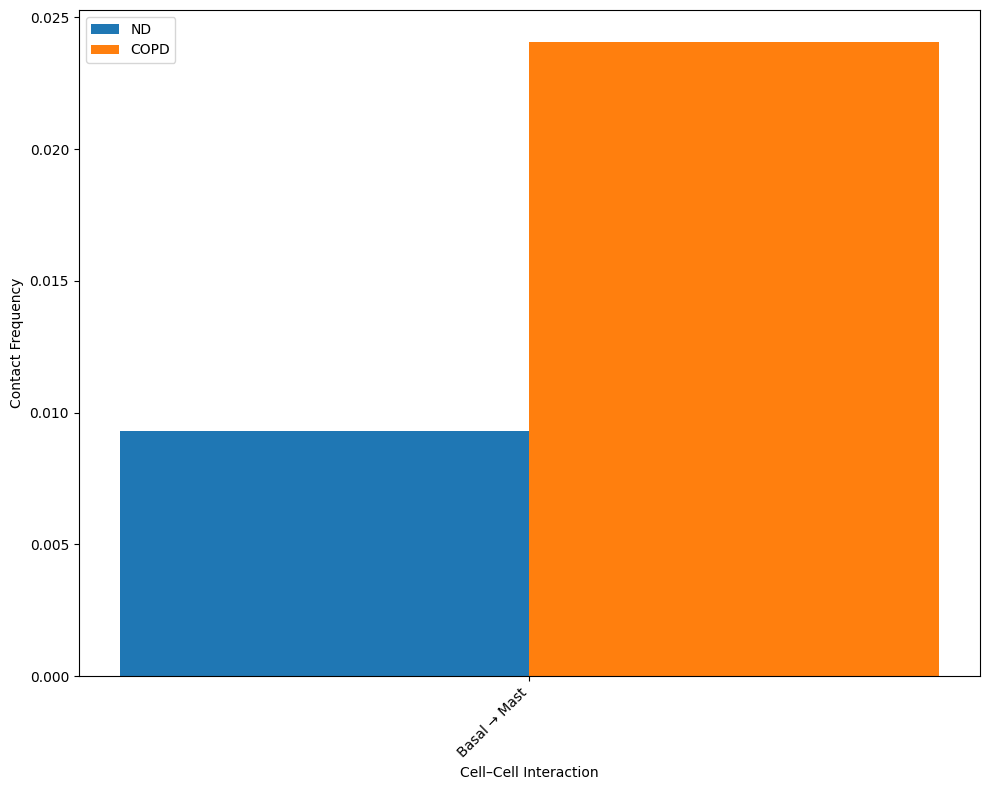

In [163]:
# basal_mast_airway_contact_hc = calculate_contact_freq(basal_mast_airway, 'HC')
# pd.DataFrame(basal_mast_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/basal_mast_hc_airway.csv')


# basal_mast_airway_contact_copd = calculate_contact_freq(basal_mast_airway, 'COPD')
# pd.DataFrame(basal_mast_airway_contact_copd).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/basal_mast_copd_airway.csv')

# plot_contact_absolute_difference(basal_mast_airway_contact_hc, basal_mast_airway_contact_copd, 'HC', 'COPD', 'basal_mast_contact_frequency_hc_copd_airway.pdf', 
#                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/')
plot_intercelltype_contacts(basal_mast_airway_contact_hc[0:1], basal_mast_airway_contact_copd[0:1],'ND',  'COPD', 'basal_mast_contact_frequency_focused_hc_copd_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/COPD/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


           GB       Sec
GB   0.815136  0.184864
Sec  0.088557  0.911443
{'Asthma'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


           GB       Sec
GB   0.746410  0.253590
Sec  0.082642  0.917358


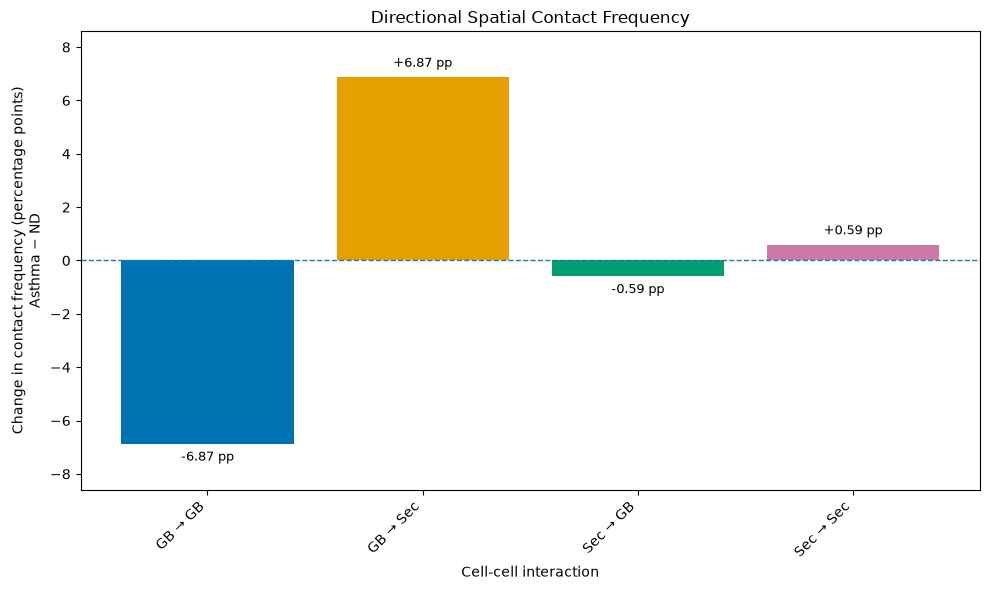

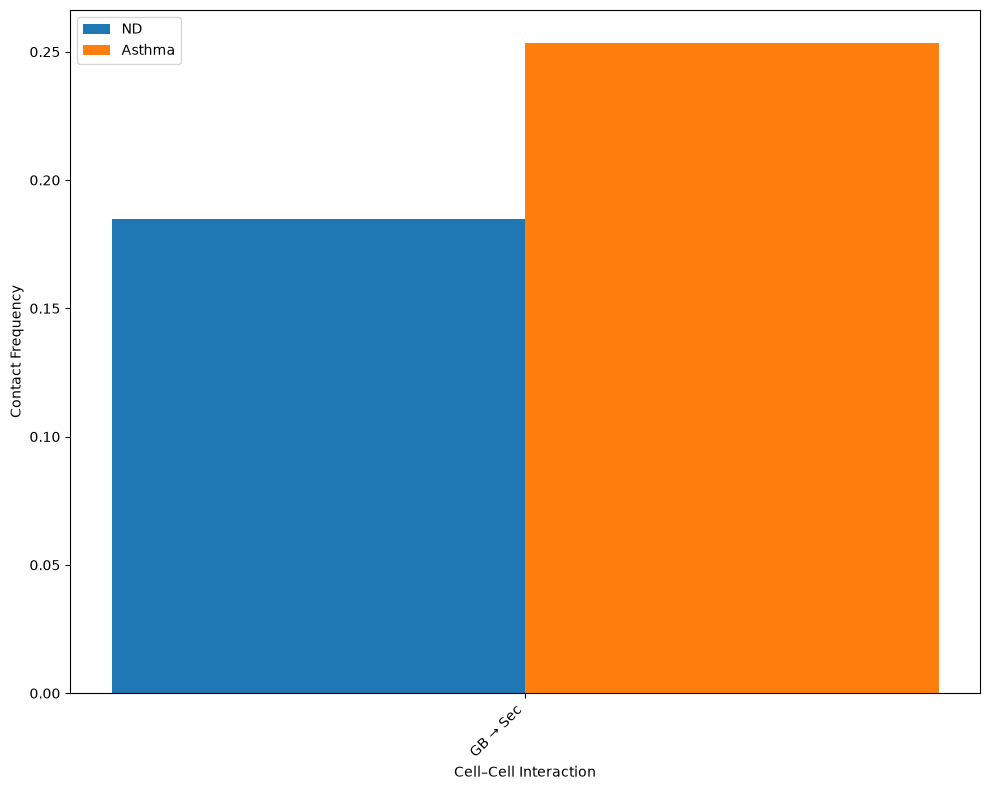

In [13]:
gb_sec_airway_contact_hc = calculate_contact_freq(gb_sec_airway, 'HC')
pd.DataFrame(gb_sec_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/gb_sec_hc_airway.csv')

gb_sec_airway_contact_asthma = calculate_contact_freq(gb_sec_airway, 'Asthma')
pd.DataFrame(gb_sec_airway_contact_asthma).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/gb_sec_asthma_airway.csv')

plot_contact_absolute_difference(gb_sec_airway_contact_hc, gb_sec_airway_contact_asthma, 'HC', 'Asthma', 'gb_sec_contact_frequency_hc_asthma_airway.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/')

plot_intercelltype_contacts(gb_sec_airway_contact_hc[0:1], gb_sec_airway_contact_asthma[0:1],'ND',  'Asthma', 'gb_sec_contact_frequency_focused_hc_asthma_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/')

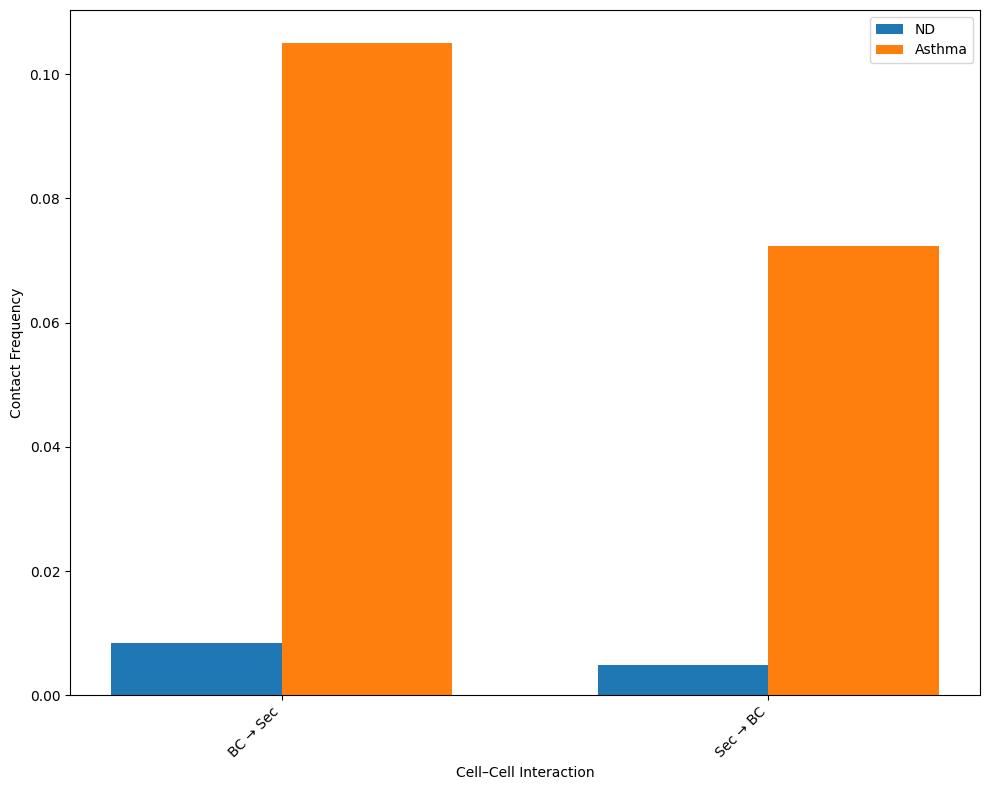

In [164]:
# bc_sec_airway_contact_hc = calculate_contact_freq(bc_sec_airway, 'HC')
# pd.DataFrame(bc_sec_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/bc_sec_hc_airway.csv')

# bc_sec_airway_contact_asthma = calculate_contact_freq(bc_sec_airway, 'Asthma')
# pd.DataFrame(bc_sec_airway_contact_asthma).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/bc_sec_asthma_airway.csv')

# plot_contact_absolute_difference(bc_sec_airway_contact_hc, bc_sec_airway_contact_asthma, 'HC', 'Asthma', 'bc_sec_contact_frequency_hc_asthma_airway.pdf', 
#                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/')
plot_intercelltype_contacts(bc_sec_airway_contact_hc, bc_sec_airway_contact_asthma,'ND',  'Asthma','bc_sec_contact_frequency_focused_hc_asthma_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Asthma/')

In [23]:
cxcl9_macs_airway_contact_hc = calculate_contact_freq(cxcl9_macs_airway, 'HC')
pd.DataFrame(cxcl9_macs_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/cxcl9_macs_hc_airway.csv')

cxcl9_macs_airway_contact_bos = calculate_contact_freq(cxcl9_macs_airway, 'BOS')
pd.DataFrame(cxcl9_macs_airway_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/cxcl9_macs_bos_airway.csv')

plot_contact_absolute_difference(cxcl9_macs_airway_contact_hc , cxcl9_macs_airway_contact_bos, 'HC', 'BOS', 'cxcl9_macs_contact_frequency_hc_bos_airway.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/')
plot_intercelltype_contacts(cxcl9_macs_airway_contact_hc.iloc[1:2, 1:3], cxcl9_macs_airway_contact_bos.iloc[1:2, 1:3],'ND',  'CLAD','cxcl9_macs_contact_frequency_focused_hc_bos_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


                  AM  CXCL9_High
AM          0.992012    0.007988
CXCL9_High  0.303103    0.696897
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


                  AM  CXCL9_High
AM          0.985692    0.014308
CXCL9_High  0.161290    0.838710


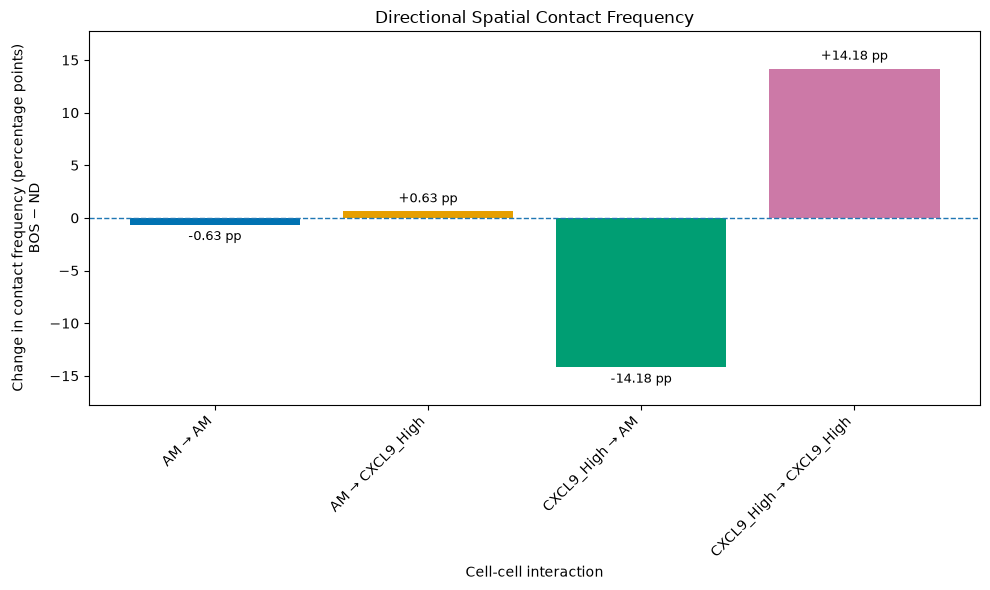

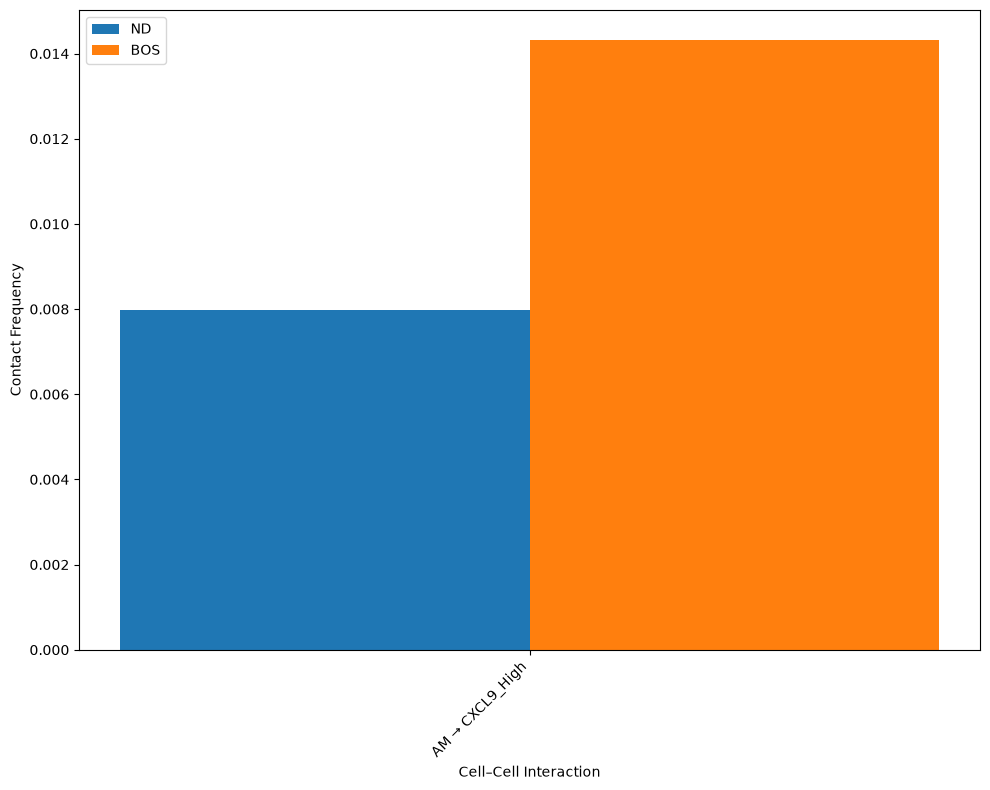

In [31]:
cxcl9_am_whole_contact_hc = calculate_contact_freq(cxcl9_am_whole, 'HC')
pd.DataFrame(cxcl9_am_whole_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_am_hc_whole.csv')

cxcl9_am_whole_contact_bos = calculate_contact_freq(cxcl9_am_whole, 'BOS')
pd.DataFrame(cxcl9_am_whole_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_am_bos_clad_whole.csv')

plot_contact_absolute_difference(cxcl9_am_whole_contact_hc , cxcl9_am_whole_contact_bos, 'HC', 'BOS', 'cxcl9_am_contact_frequency_hc_bos_whole.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

plot_intercelltype_contacts(cxcl9_am_whole_contact_hc[0:1], cxcl9_am_whole_contact_bos[0:1],'ND',  'BOS','cxcl9_am_contact_frequency_focused_hc_bos_whole.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CXCL9_High  Mono/Macs
CXCL9_High    0.517730   0.482269
Mono/Macs     0.015029   0.984971
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CXCL9_High  Mono/Macs
CXCL9_High    0.789931   0.210069
Mono/Macs     0.015029   0.984971


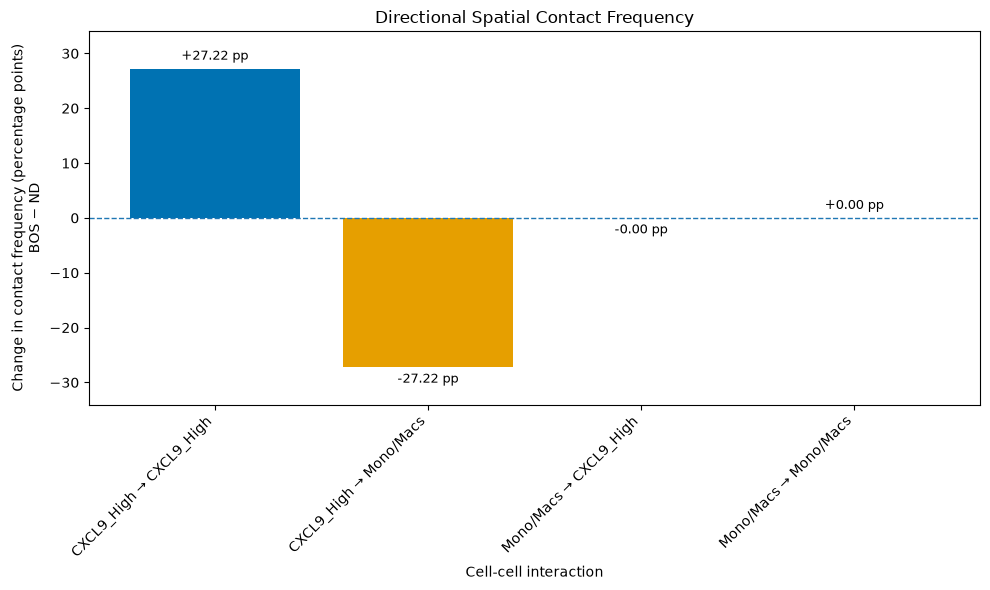

,CXCL9_High,Mono/Macs
CXCL9_High,27.220011,-27.220005
Mono/Macs,-0.000010,0.000012


In [30]:
cxcl9_macs_whole_contact_hc = calculate_contact_freq(cxcl9_macs_whole, 'HC')
pd.DataFrame(cxcl9_macs_whole_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_macs_hc_whole.csv')

cxcl9_macs_whole_contact_bos = calculate_contact_freq(cxcl9_macs_whole, 'BOS')
pd.DataFrame(cxcl9_macs_whole_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_macs_clad_whole.csv')

plot_contact_absolute_difference(cxcl9_macs_whole_contact_hc , cxcl9_macs_whole_contact_bos, 'HC', 'BOS', 'cxcl9_macs_contact_frequency_hc_bos_whole.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


               Basal  CXCL9_High
Basal       0.999061    0.000939
CXCL9_High  0.296703    0.703297
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


               Basal  CXCL9_High
Basal       0.997294    0.002706
CXCL9_High  0.590504    0.409496


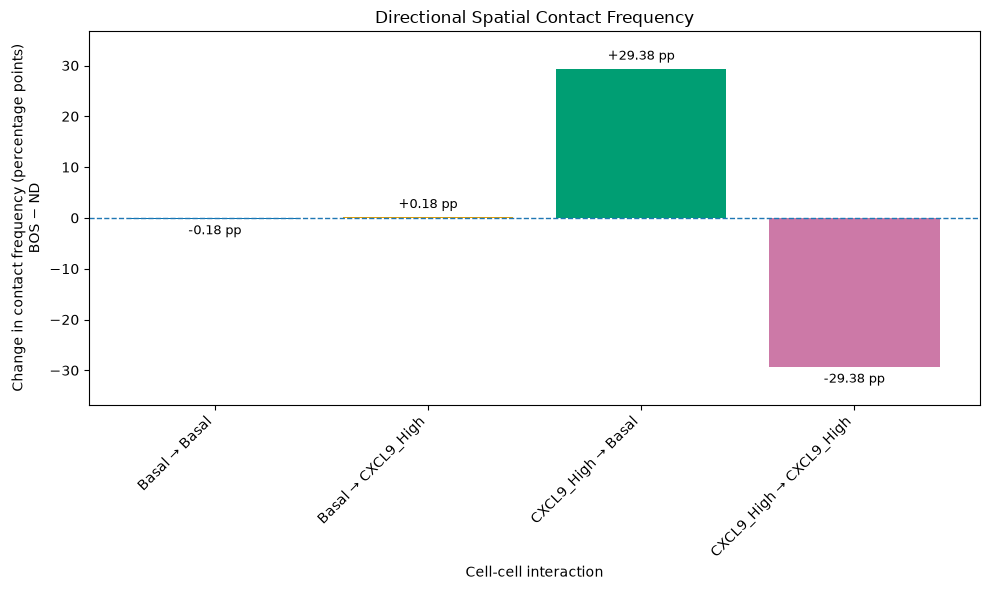

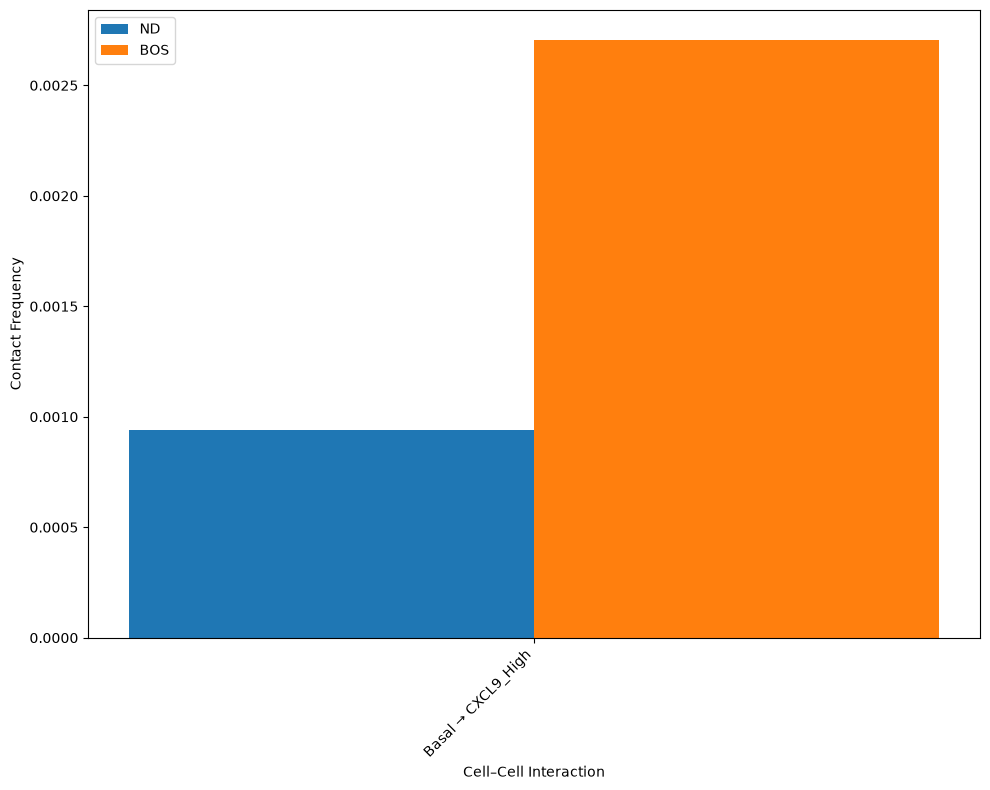

In [34]:
cxcl9_basal_airway_contact_hc = calculate_contact_freq(cxcl9_basal_airway, 'HC')
pd.DataFrame(cxcl9_basal_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/cxcl9_basal_hc_airway.csv')

cxcl9_basal_airway_contact_bos  = calculate_contact_freq(cxcl9_basal_airway, 'BOS')
pd.DataFrame(cxcl9_basal_airway_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/cxcl9_basal_bos_airway.csv')

plot_contact_absolute_difference(cxcl9_basal_airway_contact_hc , cxcl9_basal_airway_contact_bos, 'HC', 'BOS', 'cxcl9_basal_contact_frequency_hc_bos_airway.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/')

plot_intercelltype_contacts(cxcl9_basal_airway_contact_hc[0:1], cxcl9_basal_airway_contact_bos[0:1],'ND',  'BOS','cxcl9_basal_contact_frequency_focused_hc_bos_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD4 Tcells  CXCL9_High
CD4 Tcells    0.969662    0.030338
CXCL9_High    0.420635    0.579365
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD4 Tcells  CXCL9_High
CD4 Tcells    0.965347    0.034653
CXCL9_High    0.316817    0.683183


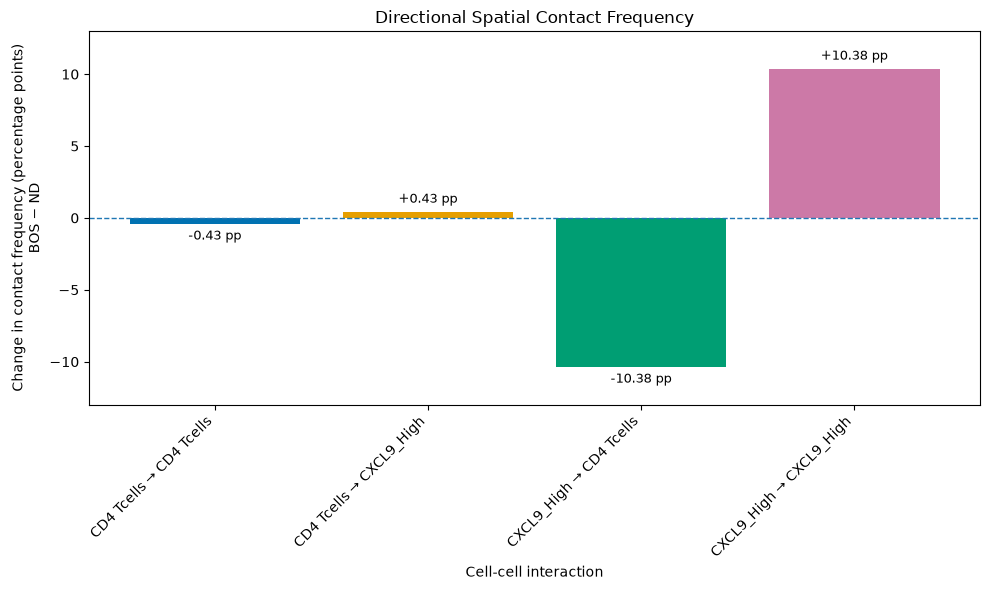

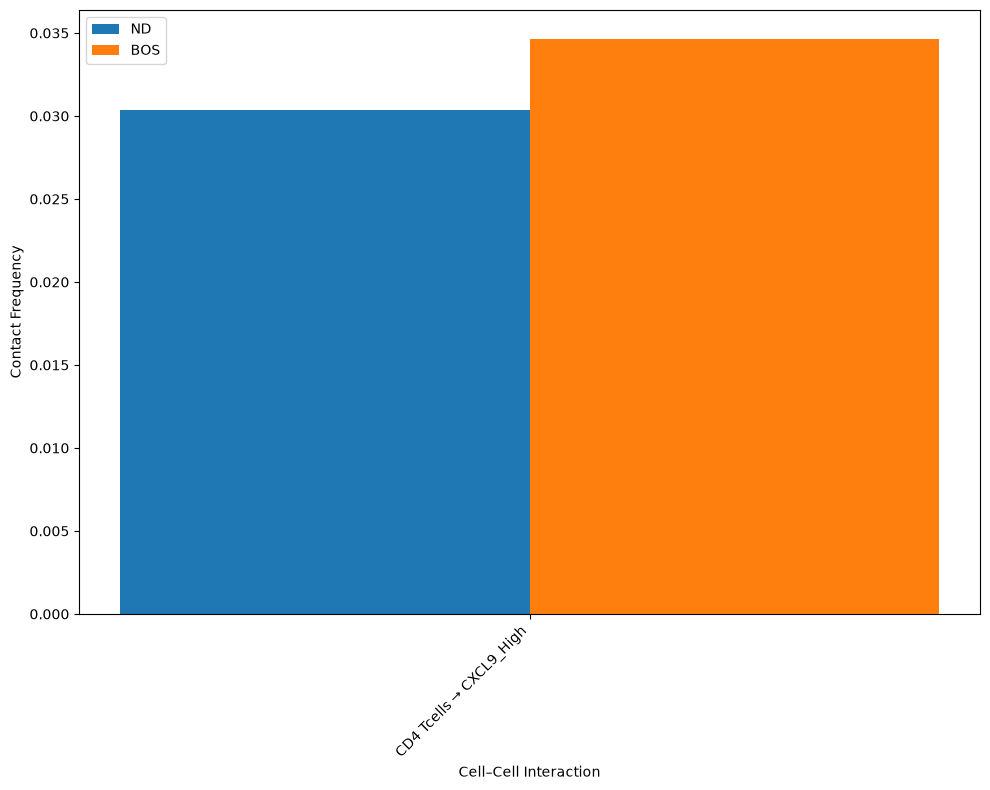

In [125]:
cxcl9_cd4_whole_contact_hc = calculate_contact_freq(cxcl9_cd4_whole, 'HC')
pd.DataFrame(cxcl9_cd4_whole_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_cd4_hc_whole.csv')

cxcl9_cd4_whole_contact_bos  = calculate_contact_freq(cxcl9_cd4_whole, 'BOS')
pd.DataFrame(cxcl9_cd4_whole_contact_bos ).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_cd4_bos_whole.csv')

plot_contact_absolute_difference(cxcl9_cd4_whole_contact_hc , cxcl9_cd4_whole_contact_bos, 'HC', 'BOS', 'cxcl9_cd4_contact_frequency_hc_bos_whole.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

plot_intercelltype_contacts(cxcl9_cd4_whole_contact_hc[0:1], cxcl9_cd4_whole_contact_bos[0:1],'ND',  'BOS','cxcl9_cd4_contact_frequency_focused_hc_bos_whole.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD8 Tcells  CXCL9_High
CD8 Tcells    0.958637    0.041363
CXCL9_High    0.367965    0.632035
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD8 Tcells  CXCL9_High
CD8 Tcells    0.948540    0.051460
CXCL9_High    0.356436    0.643564


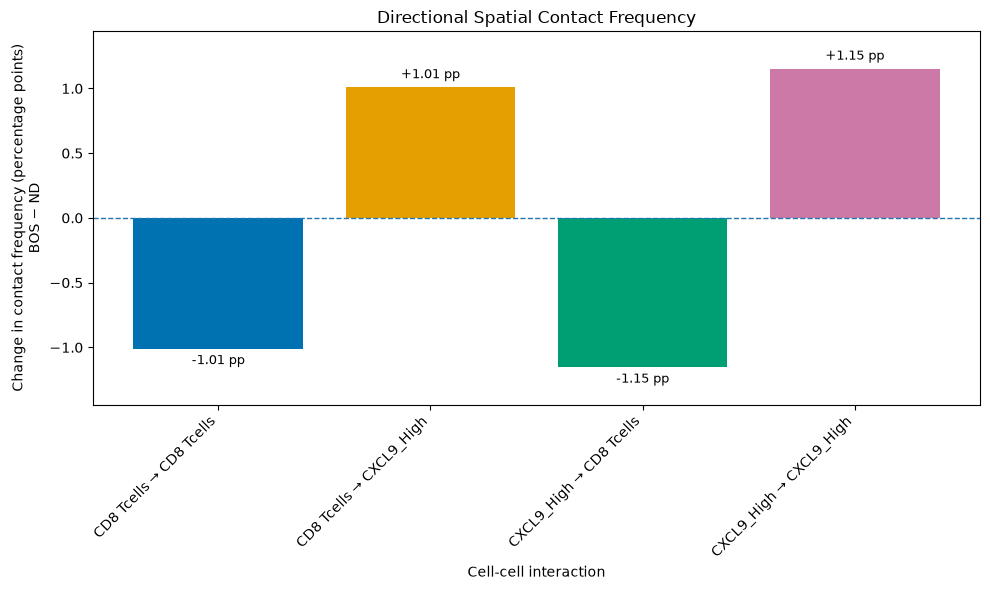

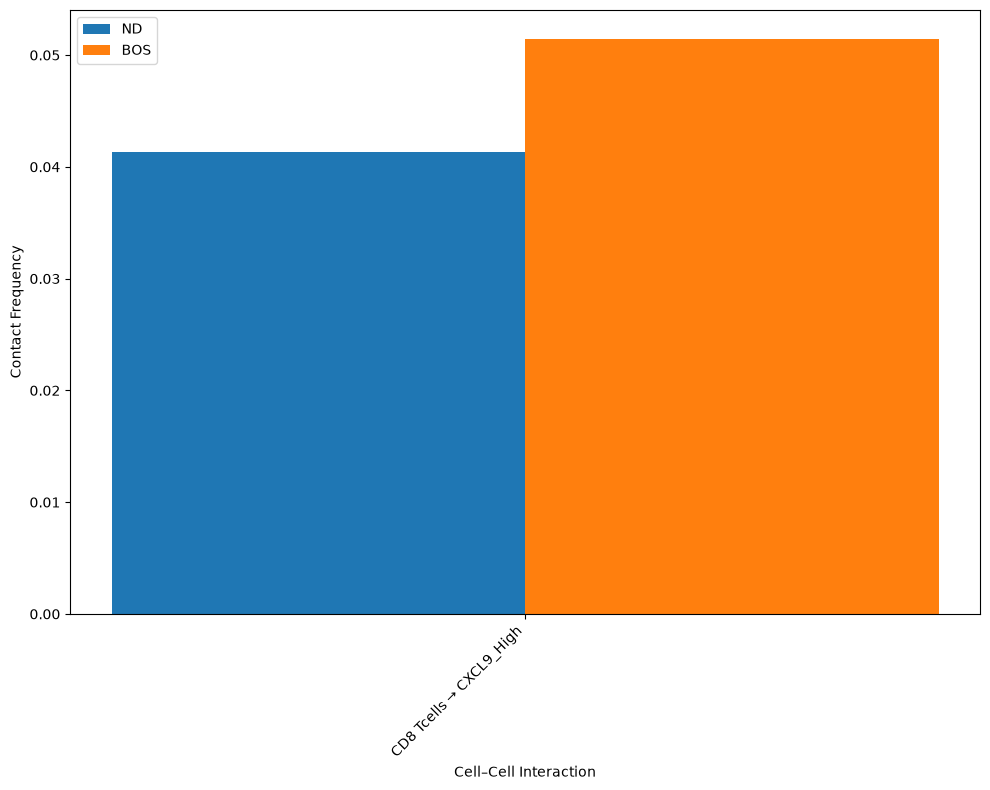

In [123]:
cxcl9_cd8_whole_contact_hc = calculate_contact_freq(cxcl9_cd8_whole, 'HC')
pd.DataFrame(cxcl9_cd8_whole_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_cd8_hc_whole.csv')

cxcl9_cd8_whole_contact_bos  = calculate_contact_freq(cxcl9_cd8_whole, 'BOS')
pd.DataFrame(cxcl9_cd8_whole_contact_bos ).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/cxcl9_cd8_bos_whole.csv')

plot_contact_absolute_difference(cxcl9_cd8_whole_contact_hc , cxcl9_cd8_whole_contact_bos, 'HC', 'BOS', 'cxcl9_cd8_contact_frequency_hc_bos_whole.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

plot_intercelltype_contacts(cxcl9_cd8_whole_contact_hc[0:1], cxcl9_cd8_whole_contact_bos[0:1],'ND',  'BOS','cxcl9_cd8_contact_frequency_focused_hc_bos_whole.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Whole_Tissue/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD8 Tcells  CXCL9_High
CD8 Tcells    0.957447    0.042553
CXCL9_High    0.319149    0.680851
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD8 Tcells  CXCL9_High
CD8 Tcells    0.963455    0.036545
CXCL9_High    0.417722    0.582278


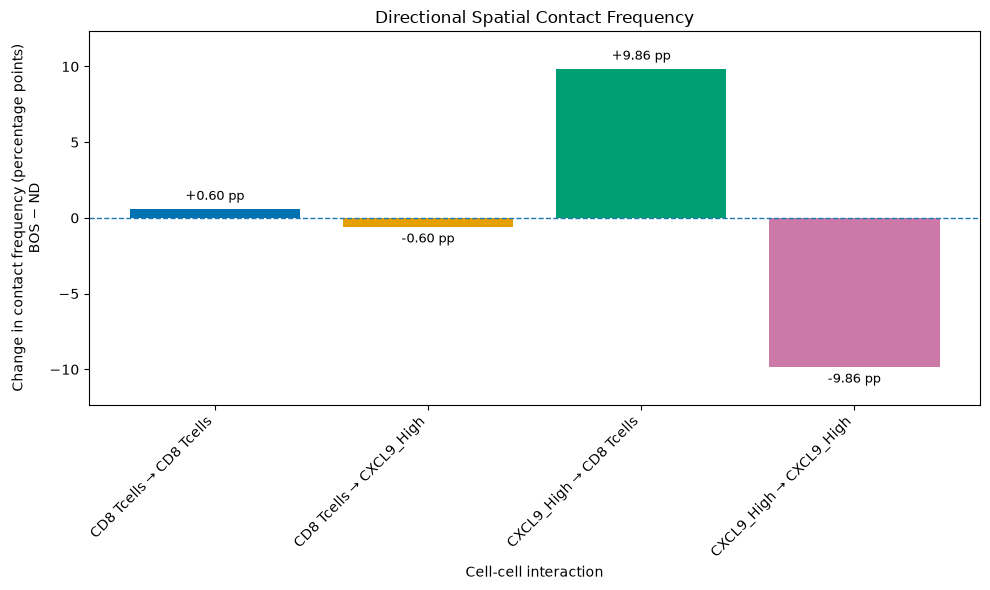

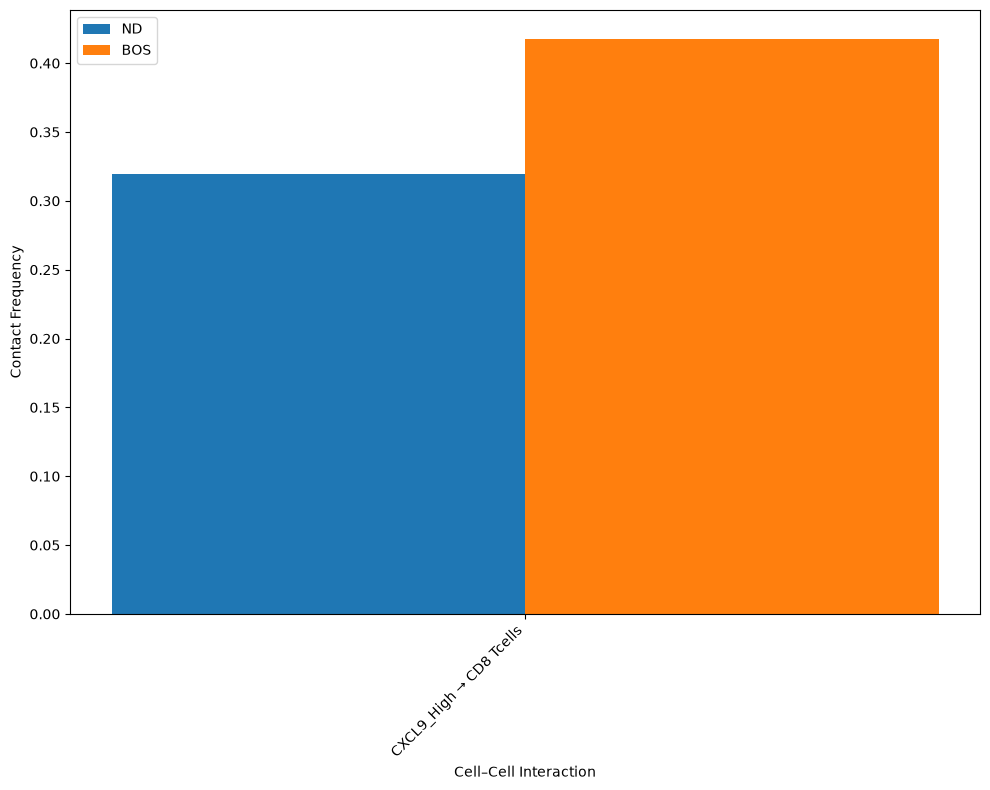

In [118]:
cxcl9_cd8_airway_contact_hc = calculate_contact_freq(cxcl9_cd8_airway, 'HC')
pd.DataFrame(cxcl9_cd8_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/cxcl9_cd8_hc_airway.csv')

cxcl9_cd8_airway_contact_bos  = calculate_contact_freq(cxcl9_cd8_airway, 'BOS')
pd.DataFrame(cxcl9_cd8_airway_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/cxcl9_cd8_bos_airway.csv')

plot_contact_absolute_difference(cxcl9_cd8_airway_contact_hc , cxcl9_cd8_airway_contact_bos, 'HC', 'BOS', 'cxcl9_cd8_contact_frequency_hc_bos_airway.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/')

plot_intercelltype_contacts(cxcl9_cd8_airway_contact_hc.iloc[:, ::-1][1:2], cxcl9_cd8_airway_contact_bos.iloc[:, ::-1][1:2],'ND',  'BOS','cxcl9_cd8_contact_frequency_focused_hc_bos_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/')

{'HC'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD4 Tcells  CXCL9_High
CD4 Tcells    0.976453    0.023547
CXCL9_High    0.381643    0.618357
{'BOS'}
INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_154100/2292241633.py:8: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(
/home/haider/miniconda3/envs/scanpy/lib/python3.11/site-packages/squidpy/gr/_utils.py:79: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


            CD4 Tcells  CXCL9_High
CD4 Tcells    0.972664    0.027336
CXCL9_High    0.326829    0.673171


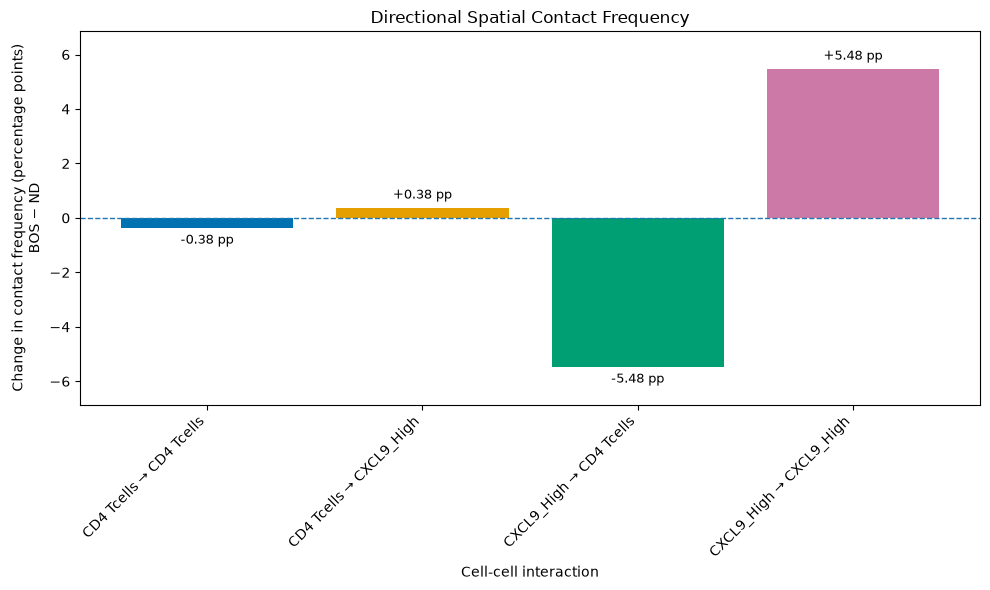

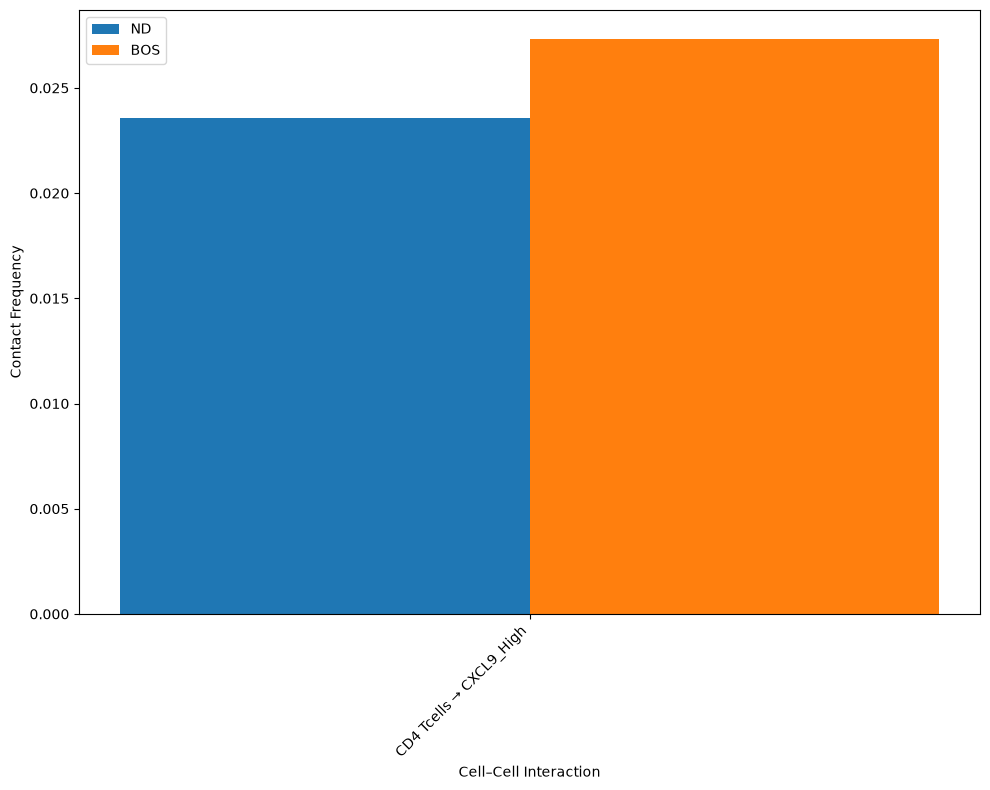

In [42]:
cxcl9_cd4_airway_contact_hc = calculate_contact_freq(cxcl9_cd4_airway, 'HC')
pd.DataFrame(cxcl9_cd4_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/cxcl9_cd4_hc_airway.csv')

cxcl9_cd4_airway_contact_bos  = calculate_contact_freq(cxcl9_cd4_airway, 'BOS')
pd.DataFrame(cxcl9_cd4_airway_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/cxcl9_cd4_bos_airway.csv')

plot_contact_absolute_difference(cxcl9_cd4_airway_contact_hc , cxcl9_cd4_airway_contact_bos, 'HC', 'BOS', 'cxcl9_cd4_contact_frequency_hc_bos_airway.pdf', 
                        '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/')

plot_intercelltype_contacts(cxcl9_cd4_airway_contact_hc[0:1], cxcl9_cd4_airway_contact_bos[0:1],'ND',  'BOS','cxcl9_cd4_contact_frequency_focused_hc_bos_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/Airway/BOS/')

In [101]:
tcell_macs_airway_contact_hc.iloc[1:2, [1,3]]

NameError: name 'tcell_macs_airway_contact_hc' is not defined

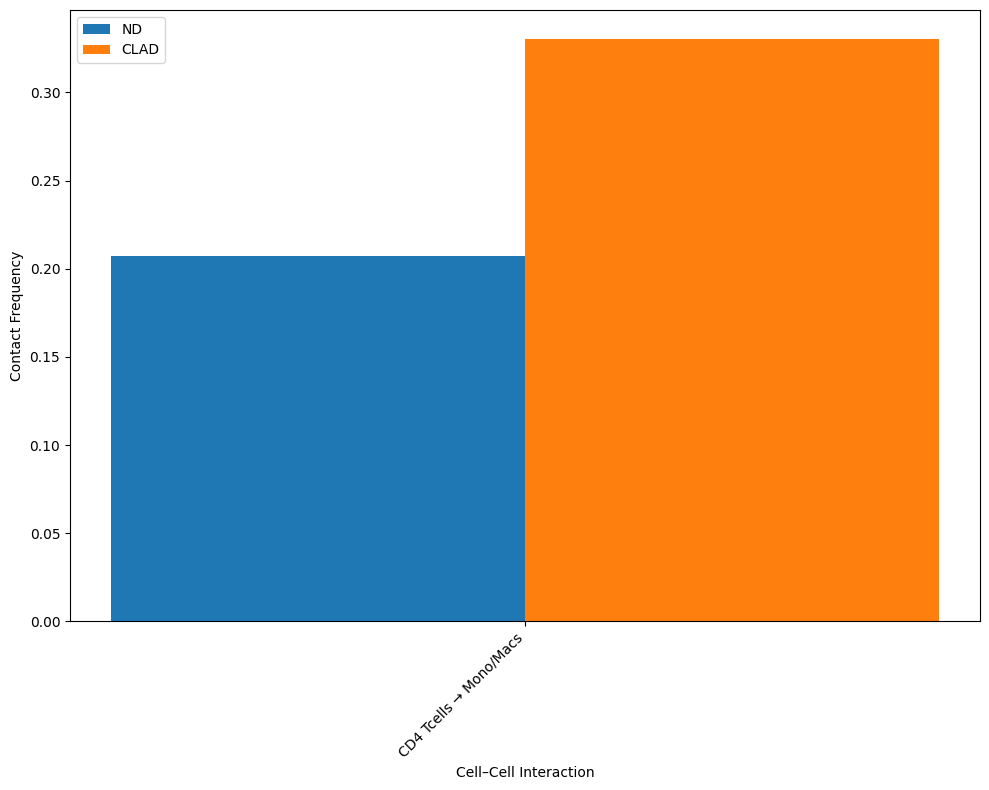

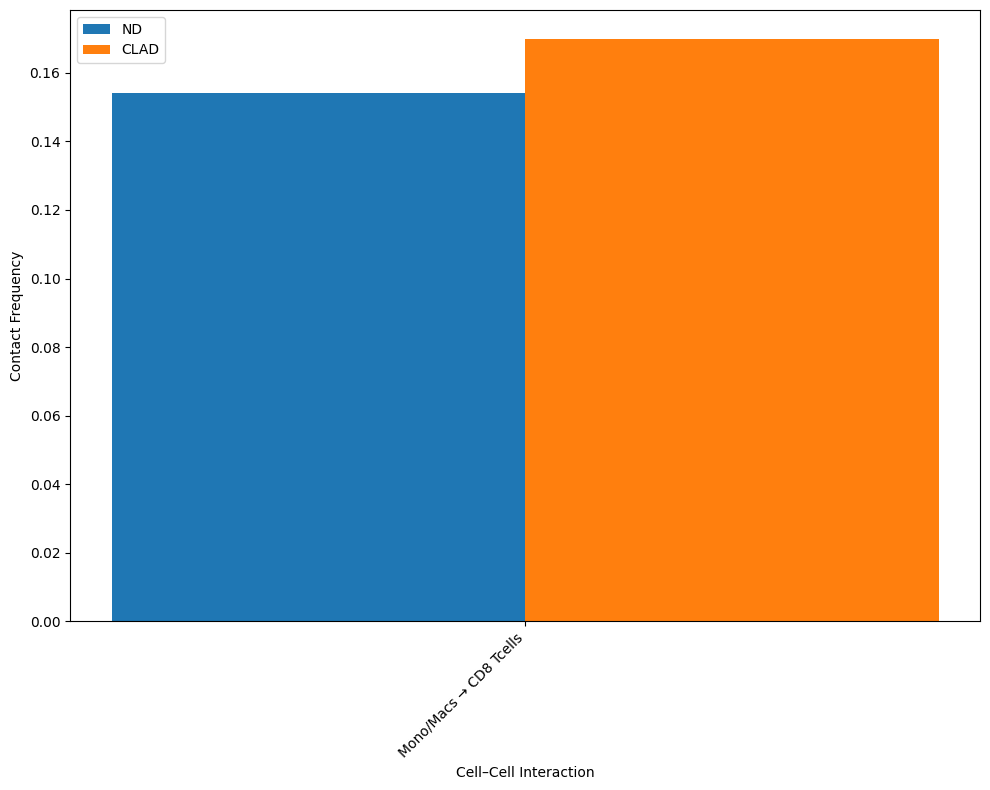

In [298]:
# tcell_macs_airway_contact_hc = calculate_contact_freq(tcell_macs_airway, 'HC')
# pd.DataFrame(tcell_macs_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/tcell_macs_hc_airway.csv')

# tcell_macs_airway_contact_bos = calculate_contact_freq(tcell_macs_airway, 'BOS')
# pd.DataFrame(tcell_macs_airway_contact_bos).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/tcell_macs_bos_airway.csv')

# plot_contact_absolute_difference(tcell_macs_airway_contact_hc , tcell_macs_airway_contact_bos, 'HC', 'BOS', 'tcell_macs_contact_frequency_hc_bos_airway.pdf', 
#                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/')
plot_intercelltype_contacts(tcell_macs_airway_contact_hc.iloc[1:2, [1,3]], tcell_macs_airway_contact_bos.iloc[1:2, [1,3]], 'ND', 'CLAD', 'CD4_macs_contact_frequency_hc_bos_airway.pdf', 
                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/')
plot_intercelltype_contacts(tcell_macs_airway_contact_hc.iloc[3:4, 1:3], tcell_macs_airway_contact_bos.iloc[3:4, 1:3], 'ND', 'CLAD', 'CD8_macs_contact_frequency_hc_bos_airway.pdf', 
                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/BOS/')


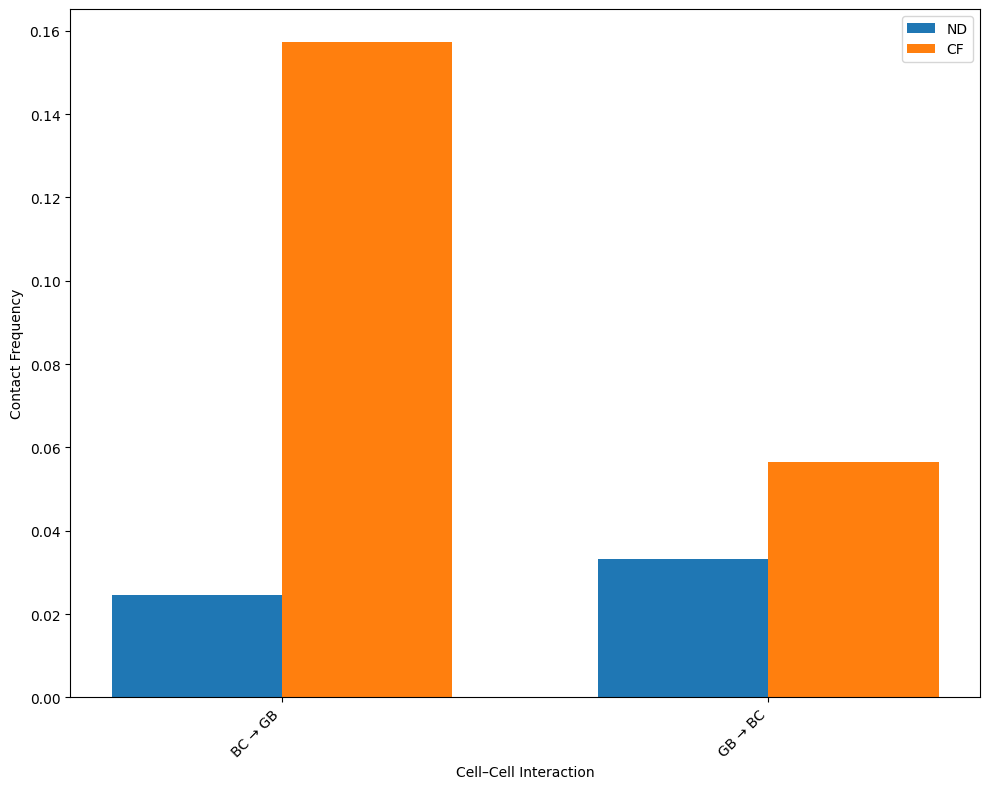

In [167]:
# bc_gb_airway_contact_hc = calculate_contact_freq(bc_gb_airway, 'HC')
# pd.DataFrame(bc_gb_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/bc_gb_airway_contact_hc.csv')

# bc_gb_airway_contact_cf = calculate_contact_freq(bc_gb_airway, 'CF')
# pd.DataFrame(bc_gb_airway_contact_cf ).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/bc_gb_airway_contact_cf.csv')


# plot_contact_absolute_difference(bc_gb_airway_contact_hc  , bc_gb_airway_contact_cf, 'HC', 'CF', 'bc_gb_contact_frequency_hc_cf_airway.pdf', 
#                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/')

plot_intercelltype_contacts(bc_gb_airway_contact_hc, bc_gb_airway_contact_cf, 'ND', 'CF','bc_gb_contact_frequency_focused_hc_cf_airway.pdf',
                            '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/')

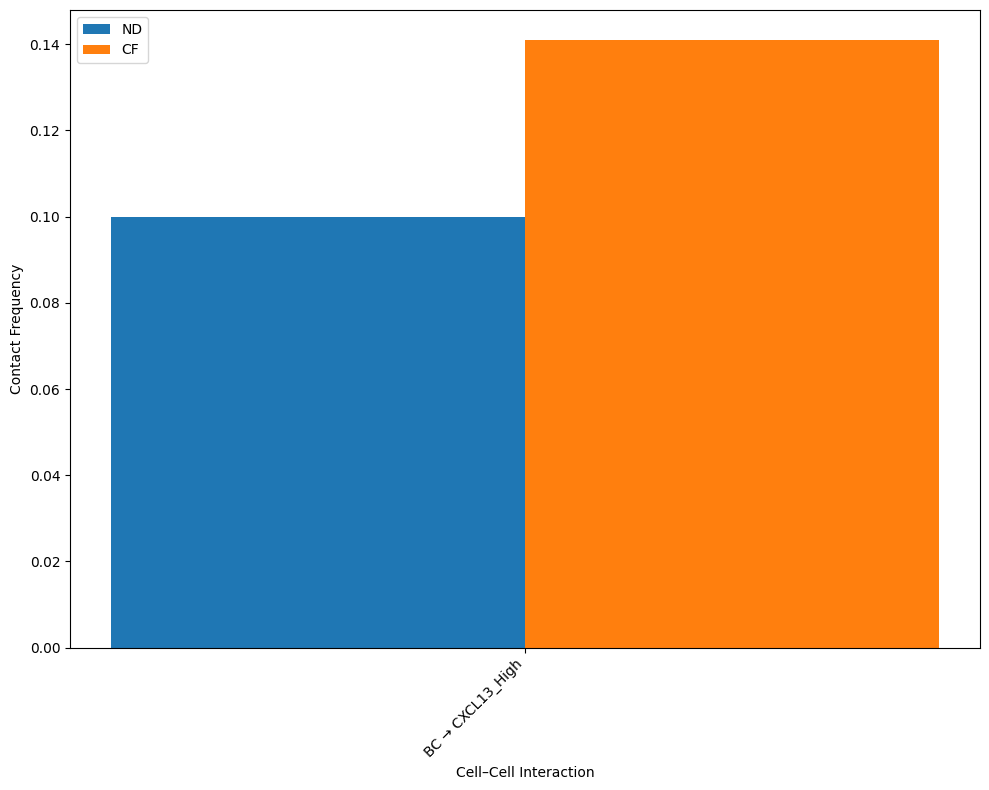

In [168]:
# cxcl13_bc_airway_contact_hc = calculate_contact_freq(cxcl13_bc_airway, 'HC')
# pd.DataFrame(cxcl13_bc_airway_contact_hc).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/cxcl13_bc_airway_contact_hc.csv')

# cxcl13_bc_airway_contact_cf = calculate_contact_freq(cxcl13_bc_airway, 'CF')
# pd.DataFrame(cxcl13_bc_airway_contact_cf).to_csv('/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/cxcl13_bc_airway_contact_cf.csv')


# plot_contact_absolute_difference(cxcl13_bc_airway_contact_hc , cxcl13_bc_airway_contact_cf, 'HC', 'CF', 'cxcl13_bc_contact_frequency_hc_cf_airway.pdf', 
#                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/')

plot_intercelltype_contacts(cxcl13_bc_airway_contact_hc[0:1], cxcl13_bc_airway_contact_cf[0:1], 'ND', 'CF', 'cxcl13_bc_contact_frequency_focused_hc_cf_airway.pdf', 
                         '/home/haider/Squidpy_Spatial_analysis/Airway/Contact_Freq_plots_Sep_2026/CF/')


In [21]:
calculate_contact_freq(basal_gb_airway, 'HC')
calculate_contact_freq(basal_gb_airway, 'CF')

{'HC'}


/home/haider/.local/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


          Basal        GB
Basal  0.985916  0.014084
GB     0.165624  0.834376
{'CF'}


/home/haider/.local/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


          Basal        GB
Basal  0.971355  0.028645
GB     0.022524  0.977476


,Basal,GB
Basal,0.971355,0.028645
GB,0.022524,0.977476


In [22]:
calculate_contact_freq(bc_gb_airway, 'HC')
calculate_contact_freq(bc_gb_airway, 'CF')

{'HC'}


/home/haider/.local/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


          BC        GB
BC  0.975526  0.024474
GB  0.033193  0.966807
{'CF'}


/home/haider/.local/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


          BC        GB
BC  0.842654  0.157346
GB  0.056501  0.943499


,BC,GB
BC,0.842654,0.157346
GB,0.056501,0.943499


In [23]:
calculate_contact_freq(cxcl13_basal_airway, 'HC')
calculate_contact_freq(cxcl13_basal_airway, 'CF')

{'HC'}


/home/haider/.local/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


                Basal  CXCL13_High
Basal        0.998367     0.001633
CXCL13_High  0.191057     0.808943
{'CF'}


/home/haider/.local/lib/python3.10/site-packages/squidpy/gr/_utils.py:203: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


                Basal  CXCL13_High
Basal        0.997073     0.002927
CXCL13_High  0.050094     0.949906


,Basal,CXCL13_High
Basal,0.997073,0.002927
CXCL13_High,0.050094,0.949906
